# Multimodal Identification of Informative Social Media Posts for Disaster Response

**Question:** does using the tweet **text + image** together find *informative* disaster posts better than text alone or image alone?

In [26]:
# Installing libraries 
%pip install -q torch torchvision transformers datasets huggingface_hub scikit-learn pandas matplotlib pillow requests tqdm

Note: you may need to restart the kernel to use updated packages.


# PART I Setting up Parameters
## 1.1 Settings

In [27]:
import os

class C:
    
    MAX_PER_SPLIT = None      
    SEEDS = [0, 1, 2]         
    RUN_ATTENTION = True      
    RUN_LOEO = True           
    NUM_WORKERS = 0           # image loading processes

    # Paths
    IMAGE_DIR = os.path.abspath("crisismmd_images")
    HF_BASE_URL = "https://huggingface.co"
    FEAT_DIR = os.path.abspath("features")          
    RES_DIR = os.path.abspath("results")            
    FIG_DIR = os.path.join(RES_DIR, "figures")      # plots

    #  Data 
    HF_DATASET = "QCRI/CrisisMMD"
    HF_CONFIG = "informative"
    SPLITS = ["train", "dev", "test"]
    POSITIVE_CLASS = "informative"                  # y = 1 means informative

    TEXT_MODEL= "distilbert-base-uncased"
    TEXT_MAX_LEN= 64
    IMAGE_SIZE= 224
    EXTRACT_BATCH=64
    BATCH_SIZE= 64 #Training
    EPOCHS =40                # upper limit, early stopping ends sooner
    PATIENCE= 6               # stop if dev macro-F1 does not improve for 6 epochs
    LR=1e-3                  # MLP models
    LR_ATTN = 3e-4             # cross-attention model
    WEIGHT_DECAY = 1e-4
    DROPOUT =0.3
    HIDDEN =256
    N_HEADS =4
    #Evaluation 
    MC_PASSES =30             # Monte Carlo dropout pass
    THRESHOLD =0.5

for d in (C.FEAT_DIR, C.RES_DIR, C.FIG_DIR):
    os.makedirs(d, exist_ok=True)

## 1.2 Data loading, text and image preprocessing 


In [28]:
import html
import os
import re
import numpy as np
import pandas as pd

# 1. Loading
def load_crisismmd():

    from datasets import load_dataset
    try:
        ds = load_dataset(C.HF_DATASET, C.HF_CONFIG)
    except Exception as e:
        print("Standard loading failed, reading raw JSON instead:", repr(e)[:200])
        from huggingface_hub import hf_hub_download
        files = {s: hf_hub_download(C.HF_DATASET, f"{C.HF_CONFIG}/{s}.json", repo_type="dataset")
                 for s in C.SPLITS}
        ds = load_dataset("json", data_files=files)
    for s in C.SPLITS:
        if "image" in ds[s].column_names:
            ds[s] = ds[s].remove_columns("image")
    return ds

def to_dataframe(ds):
    feat = ds["train"].features["label"]
    if hasattr(feat, "names"):# ClassLabel: 0=informative, 1=not
        pos = feat.names.index(C.POSITIVE_CLASS)
    else:
        pos = C.POSITIVE_CLASS
    frames = []
    for split in C.SPLITS:
        cols = [c for c in ds[split].column_names if c != "image"]
        df = ds[split].select_columns(cols).to_pandas()
        df["split"] = split
        df["row"] = np.arange(len(df))# position inside its split
        frames.append(df)
    df = pd.concat(frames, ignore_index=True)
    df["y"] = (df["label"] == pos).astype(int)
    df["tweet_text"] = df["tweet_text"].fillna("")
    df["clean_text"] = df["tweet_text"].map(clean_text)
    return df

# 2. Text preprocessing
_URL = re.compile(r"https?://\S+|www\.\S+")
_USER = re.compile(r"@\w+")
_RT = re.compile(r"^RT\s+", flags=re.IGNORECASE)
_SPACE = re.compile(r"\s+")


def clean_text(t: str) -> str:
    t = html.unescape(str(t))
    t = _RT.sub("", t)
    t = _URL.sub(" ", t)
    t = _USER.sub("@user", t)
    t = t.replace("#", " ")
    return _SPACE.sub(" ", t).strip()


#  Images: download straight from the Hugging Face 
def _repo_path(image_path):
    p = str(image_path).lstrip("/")
    return p if p.startswith("data_image/") else "data_image/" + p


def local_image_path(image_path):
    return os.path.join(C.IMAGE_DIR, _repo_path(image_path))


def image_url(image_path):
    from urllib.parse import quote
    return f"{C.HF_BASE_URL}/datasets/{C.HF_DATASET}/resolve/main/{quote(_repo_path(image_path))}"


def _hf_token():
    tok = os.environ.get("HF_TOKEN")
    if tok:
        return tok
    try:
        from huggingface_hub import get_token
        return get_token()
    except Exception:
        return None


def download_images(image_paths, workers=8, max_tries=6, timeout=60):
    import random
    import threading
    import time
    from concurrent.futures import ThreadPoolExecutor, as_completed

    import requests
    from tqdm.auto import tqdm

    todo = [p for p in dict.fromkeys(image_paths) if not os.path.exists(local_image_path(p))]
    total = len(set(image_paths))
    print(f"Images: {total - len(todo):,} of {total:,} already on disk, {len(todo):,} to download"
          f" -> {os.path.join(C.IMAGE_DIR, 'data_image')}")
    if not todo:
        return []

    token = _hf_token()
    headers = {"User-Agent": "crisismmd-course-project"}
    if token:
        headers["Authorization"] = f"Bearer {token}"   
    else:
        print("Not logged in to Hugging Face. ")
    local = threading.local()

    def session():
        if not hasattr(local, "s"):
            local.s = requests.Session()
            local.s.headers.update(headers)
        return local.s

    def fetch(p):
        dest = local_image_path(p)
        os.makedirs(os.path.dirname(dest), exist_ok=True)
        last = None
        for attempt in range(max_tries):
            try:
                r = session().get(image_url(p), timeout=timeout, allow_redirects=True)
                if r.status_code == 200 and r.content:
                    tmp = dest + ".part"
                    with open(tmp, "wb") as f:
                        f.write(r.content)
                    os.replace(tmp, dest)
                    return p, None
                if r.status_code == 404:
                    return p, "404 not found"
                last = f"HTTP {r.status_code}"
                wait = float(r.headers.get("Retry-After", 0) or 0) if r.status_code == 429 else 0
            except Exception as e:# timeout
                last, wait = repr(e)[:100], 0
            time.sleep(max(wait, 2 ** attempt) + random.random())   # retry
        return p, last

    failed = []
    with ThreadPoolExecutor(max_workers=workers) as pool:
        jobs = [pool.submit(fetch, p) for p in todo]
        bar = tqdm(as_completed(jobs), total=len(jobs), desc="Downloading images", unit="img")
        for job in bar:
            p, err = job.result()
            if err:
                failed.append((p, err))
                bar.set_postfix(failed=len(failed))
    ok = total - len(failed)
    print(f"Done: {ok:,} of {total:,} images on disk." + (" All images ready." if not failed else
          f" {len(failed)} failed - run this cell again to retry them."))
    for p, err in failed[:5]:
        print("   failed:", p, "->", err)
    return failed


def get_image(ds_split, i, image_path=None):
    from PIL import Image
    try:
        return Image.open(local_image_path(image_path)).convert("RGB"), True
    except Exception:
        return Image.new("RGB", (C.IMAGE_SIZE, C.IMAGE_SIZE)), False


def image_transform():
    import torchvision.transforms as T
    return T.Compose([
        T.Resize(256),
        T.CenterCrop(C.IMAGE_SIZE),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])


# 4. Data quality report
def quality_report(df: pd.DataFrame) -> dict:
    rep = {}
    rep["n_rows"] = {s: int((df.split == s).sum()) for s in C.SPLITS}
    rep["missing_text"] = int((df.tweet_text.str.strip() == "").sum())
    rep["empty_after_cleaning"] = int((df.clean_text == "").sum())
    rep["missing_image_path"] = int(df.image_path.isna().sum()) if "image_path" in df else None
    rep["pct_informative"] = {s: round(100 * df[df.split == s].y.mean(), 1) for s in C.SPLITS}

    words = df.clean_text.str.split().str.len()
    rep["words_mean"] = round(float(words.mean()), 1)
    rep["words_p99"] = int(np.percentile(words, 99))

    dup = df.duplicated("clean_text",keep=False)
    rep["rows_with_duplicated_text"]= int(dup.sum())
    rep["exact_duplicate_rows"] =int(df.duplicated(["tweet_text", "image_path"]).sum())
    g = df.groupby("clean_text").y.nunique()     # Same text with DIFFERENT labels
    rep["texts_with_conflicting_labels"] = int((g > 1).sum())
    train_txt = set(df[df.split =="train"].clean_text) 
    test = df[df.split == "test"]
    rep["test_texts_seen_in_train"] =int(test.clean_text.isin(train_txt).sum())
    rep["tweets_with_multiple_images"] = int((df.groupby("tweet_id").size() > 1).sum())

    rep["events"] = df.groupby("event_name").size().sort_values(ascending=False).to_dict()
    rep["pct_informative_by_event"] = (df.groupby("event_name").y.mean() * 100).round(1).to_dict()
    return rep


def add_seen_flag(df: pd.DataFrame) -> pd.DataFrame:
    train_txt = set(df[df.split == "train"].clean_text)
    df["text_seen_in_train"] = df.clean_text.isin(train_txt) & (df.split != "train")
    return df

In [29]:
def subset(ds):
    if C.MAX_PER_SPLIT:
        for s in C.SPLITS:
            ds[s] = ds[s].select(range(min(C.MAX_PER_SPLIT, len(ds[s]))))
    return ds

## 1.4 Feature extraction with frozen pretrained encoders
* **Text:** DistilBERT to a 768-d vector for each token and one mean-pooled 768-d vector per tweet.
* **Image:** EfficientNet-B0 to a 7×7 grid of 1280-d region vectors and one pooled 1280-d vector.


In [30]:
import os
import time

import numpy as np
from numpy.lib.format import open_memmap

def _path(name, split):
    return os.path.join(C.FEAT_DIR, f"{name}_{split}.npy")

def features_exist(split):
    names = ["text_pooled", "text_tokens", "text_mask", "img_pooled", "img_tokens", "img_ok"]
    return all(os.path.exists(_path(n, split)) for n in names)
# Text
def extract_text(texts, split, device):
    import torch
    from transformers import AutoModel, AutoTokenizer

    tok = AutoTokenizer.from_pretrained(C.TEXT_MODEL)
    bert = AutoModel.from_pretrained(C.TEXT_MODEL).to(device).eval()
    n, L = len(texts), C.TEXT_MAX_LEN
    pooled = open_memmap(_path("text_pooled", split), "w+", np.float32, (n, 768))
    tokens = open_memmap(_path("text_tokens", split), "w+", np.float16, (n, L, 768))
    masks = open_memmap(_path("text_mask", split), "w+", np.bool_, (n, L))

    t0 = time.time()
    with torch.no_grad():
        for s in range(0, n, C.EXTRACT_BATCH):
            batch = list(texts[s:s + C.EXTRACT_BATCH])
            enc = tok(batch, padding="max_length", truncation=True, max_length=L,
                      return_tensors="pt").to(device)
            h = bert(**enc).last_hidden_state
            m = enc["attention_mask"].unsqueeze(-1).float()
            pooled[s:s + len(batch)] = ((h * m).sum(1) / m.sum(1)).cpu().numpy()
            tokens[s:s + len(batch)] = h.half().cpu().numpy()
            masks[s:s + len(batch)] = enc["attention_mask"].bool().cpu().numpy()
    for a in (pooled, tokens, masks):
        a.flush()
    return time.time() - t0


# Image
class _ImageSet:

    def __init__(self, ds_split, paths):
        self.ds, self.paths, self.tf = ds_split, list(paths), image_transform()

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, i):
        import torch
        img, ok = get_image(self.ds, i, self.paths[i])
        return self.tf(img), torch.tensor(ok)


def extract_images(ds_split, paths, split, device, workers=C.NUM_WORKERS):
    import torch
    from torch.utils.data import DataLoader
    from torchvision.models import EfficientNet_B0_Weights, efficientnet_b0

    cnn = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1).to(device).eval()
    n = len(ds_split)
    pooled = open_memmap(_path("img_pooled", split), "w+", np.float32, (n, 1280))
    tokens = open_memmap(_path("img_tokens", split), "w+", np.float16, (n, 49, 1280))
    oks = np.zeros(n, dtype=bool)

    loader = DataLoader(_ImageSet(ds_split, paths), batch_size=C.EXTRACT_BATCH,
                        num_workers=workers, shuffle=False)
    t0, s = time.time(), 0
    with torch.no_grad():
        for x, ok in loader:
            fmap = cnn.features(x.to(device))                      
            b = fmap.shape[0]
            pooled[s:s + b] =fmap.mean(dim=(2, 3)).cpu().numpy() 
            tokens[s:s + b] =fmap.flatten(2).transpose(1, 2).half().cpu().numpy()
            oks[s:s + b] = ok.numpy()
            s += b
    pooled.flush(); tokens.flush()
    np.save(_path("img_ok", split), oks)
    return time.time() - t0


def extract_all(ds, df, device):
    times = {}
    for split in C.SPLITS:
        if features_exist(split):
            print(f"[{split}] features found, skipping")
            continue
        part = df[df.split == split].sort_values("row")
        print(f"[{split}] text ...")
        tt = extract_text(part.clean_text.tolist(), split, device)
        print(f"[{split}] images ...")
        ti = extract_images(ds[split], part.image_path.tolist(), split, device)
        times[split] = {"text_sec": round(tt, 1), "image_sec": round(ti, 1)}
        print(f"[{split}] done: {times[split]}")
    return times

# Loading saved features
def load_pooled(split):
    return {
        "text": np.load(_path("text_pooled", split)),
        "image": np.load(_path("img_pooled", split)),
        "img_ok": np.load(_path("img_ok", split)),
    }

def load_tokens(split):
    return {
        "text_tokens": np.load(_path("text_tokens", split), mmap_mode="r"),
        "text_mask": np.load(_path("text_mask", split), mmap_mode="r"),
        "img_tokens": np.load(_path("img_tokens", split), mmap_mode="r"),
    }

## 1.5 Defining Models

In [31]:
import torch
import torch.nn as nn



class MLPHead(nn.Module):

    def __init__(self, in_dim, hidden=C.HIDDEN, dropout=C.DROPOUT):
        super().__init__()
        self.net = nn.Sequential(
            nn.Dropout(0.1),
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


class CrossAttnBlock(nn.Module):

    def __init__(self, hidden=C.HIDDEN, heads=C.N_HEADS, dropout=0.1):
        super().__init__()
        self.attn = nn.MultiheadAttention(hidden, heads, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(hidden)
        self.ff = nn.Sequential(nn.Linear(hidden, 4 * hidden), nn.ReLU(),
                                nn.Dropout(dropout), nn.Linear(4 * hidden, hidden))
        self.norm2 = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(dropout)

    def forward(self, q, ctx, ctx_pad_mask=None):
        out, w = self.attn(q, ctx, ctx, key_padding_mask=ctx_pad_mask)
        x = self.norm1(q + self.drop(out))
        x = self.norm2(x + self.drop(self.ff(x)))
        return x, w


class CrossAttnFusion(nn.Module):

    def __init__(self, text_dim=768, img_dim=1280, hidden=C.HIDDEN, heads=C.N_HEADS,
                 dropout=C.DROPOUT):
        super().__init__()
        self.text_proj = nn.Sequential(nn.Linear(text_dim, hidden), nn.LayerNorm(hidden))
        self.img_proj = nn.Sequential(nn.Linear(img_dim, hidden), nn.LayerNorm(hidden))
        self.img_pos = nn.Parameter(torch.zeros(1, 49, hidden))
        self.t2i = CrossAttnBlock(hidden, heads)
        self.i2t = CrossAttnBlock(hidden, heads)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * hidden, hidden),
                                  nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 1))

    def forward(self, text_tok, text_mask, img_tok, return_attn=False):
        T = self.text_proj(text_tok)
        I = self.img_proj(img_tok) + self.img_pos
        pad = ~text_mask# True = padding

        T2, w_t2i = self.t2i(T, I)# words attend to regions
        I2, w_i2t = self.i2t(I, T, ctx_pad_mask=pad)

        m = text_mask.unsqueeze(-1).float()
        t_vec = (T2*m).sum(1) /m.sum(1).clamp(min=1)
        i_vec = I2.mean(1)
        logit = self.head(torch.cat([t_vec,i_vec], dim=-1)).squeeze(-1)
        if return_attn:
            return logit, w_t2i, w_i2t
        return logit

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## 1.6 Training loop, prediction and Monte Carlo dropout

In [32]:
import copy
import random
import time

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import f1_score



def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")

class VectorFeeder:
    def __init__(self, X_by_split):
        tr = X_by_split["train"]
        self.mu, self.sd = tr.mean(0), tr.std(0) + 1e-6
        self.X = {s: torch.tensor((x - self.mu) / self.sd, dtype=torch.float32)
                  for s, x in X_by_split.items()}
        self.dim = tr.shape[1]

    def n(self, split):
        return len(self.X[split])
    def logits(self, model, split, idx):
        return model(self.X[split][idx].to(DEVICE))

class TokenFeeder:
    def __init__(self, tok_by_split):
        self.T = {s: torch.from_numpy(np.array(d["text_tokens"])) for s, d in tok_by_split.items()}
        self.M = {s: torch.from_numpy(np.array(d["text_mask"])) for s, d in tok_by_split.items()}
        self.I = {s: torch.from_numpy(np.array(d["img_tokens"])) for s, d in tok_by_split.items()}
    def n(self, split):
        return len(self.T[split])

    def logits(self, model, split, idx):
        return model(self.T[split][idx].to(DEVICE).float(),
                     self.M[split][idx].to(DEVICE),
                     self.I[split][idx].to(DEVICE).float())

@torch.no_grad() # Prediction
def predict_proba(model, feeder, split, mc_dropout=False, batch=256):
    """Probability of 'informative' for every row. mc_dropout=True keeps dropout ON."""
    model.train() if mc_dropout else model.eval()   
    out = []
    n = feeder.n(split)
    for s in range(0, n, batch):
        idx = torch.arange(s, min(s + batch, n))
        out.append(torch.sigmoid(feeder.logits(model, split, idx)).float().cpu())
    model.eval()
    return torch.cat(out).numpy()

def mc_dropout(model, feeder, split, passes=C.MC_PASSES):
    P = np.stack([predict_proba(model, feeder, split, mc_dropout=True) for _ in range(passes)])
    return P.mean(0), P.std(0)

def _bce(p, y, pos_weight):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return float(np.mean(-(pos_weight * y * np.log(p) + (1 - y) * np.log(1 - p))))

def train_model(model, feeder, y, lr=C.LR, seed=0, epochs=C.EPOCHS, patience=C.PATIENCE,
                train_split="train", dev_split="dev", verbose=True):# Model Training
    set_seed(seed)
    model = model.to(DEVICE)
    y_tr = y[train_split]
    pos_weight = float((y_tr == 0).sum() / max((y_tr == 1).sum(), 1))
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight, device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=C.WEIGHT_DECAY)
    y_t = torch.tensor(y_tr, dtype=torch.float32)

    hist = {k: [] for k in ["train_loss", "dev_loss", "train_f1", "dev_f1"]}
    best_f1, best_state, wait = -1, None, 0
    g = torch.Generator().manual_seed(seed)
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(feeder.n(train_split), generator=g)
        for s in range(0, len(perm), C.BATCH_SIZE):
            idx = perm[s:s + C.BATCH_SIZE]
            opt.zero_grad()
            loss = loss_fn(feeder.logits(model, train_split, idx), y_t[idx].to(DEVICE))
            loss.backward()
            opt.step()
        for split, tag in [(train_split, "train"), (dev_split, "dev")]:# evaluate on train and dev
            p = predict_proba(model, feeder, split)
            hist[f"{tag}_loss"].append(_bce(p, y[split], pos_weight))
            hist[f"{tag}_f1"].append(f1_score(y[split], p >= C.THRESHOLD, average="macro"))
        if verbose:
            print(f"  ep {ep + 1:2d}  train loss {hist['train_loss'][-1]:.3f} F1 {hist['train_f1'][-1]:.3f}"
                  f" | dev loss {hist['dev_loss'][-1]:.3f} F1 {hist['dev_f1'][-1]:.3f}")

        if hist["dev_f1"][-1] > best_f1:
            best_f1, best_state, wait = hist["dev_f1"][-1], copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    train_sec = time.time() - t0
    model.load_state_dict(best_state)
    hist["best_epoch"] = int(np.argmax(hist["dev_f1"]) + 1)
    return model, hist, train_sec

def time_inference(model, feeder, split="test"):
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    predict_proba(model, feeder, split)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return 1000 * (time.time() - t0)/feeder.n(split)*1000

## 1.7 Metrics

In [33]:
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score,precision_score, recall_score, roc_auc_score)

def all_metrics(y, p, thr=C.THRESHOLD):
    y = np.asarray(y)
    p = np.asarray(p)
    yhat = (p >= thr).astype(int)
    out = {
        "macro_f1": f1_score(y, yhat, average="macro"),
        "accuracy": accuracy_score(y, yhat),
        "precision": precision_score(y, yhat, average="macro", zero_division=0),
        "recall": recall_score(y, yhat, average="macro", zero_division=0),
        "recall_inf": recall_score(y, yhat, pos_label=1, zero_division=0),
        "recall_notinf": recall_score(y, yhat, pos_label=0, zero_division=0),
    }
    if len(np.unique(y)) == 2:
        out["auroc"] = roc_auc_score(y, p)
        out["auprc"] = average_precision_score(y, p)
    else:
        out["auroc"] = out["auprc"] = np.nan
    return out

def summarise(rows: pd.DataFrame, by="model", cols=("macro_f1", "accuracy", "precision",
                                                     "recall", "recall_inf", "auroc")):
    g = rows.groupby(by)[list(cols)]
    mean, std = g.mean(), g.std().fillna(0)
    table = mean.copy().astype(object)
    for c in cols:
        table[c] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(mean[c], std[c])]
    return table, mean, std

def best_late_weight(y_dev, p_text_dev, p_img_dev, grid=np.linspace(0, 1, 21)):
    scores = [f1_score(y_dev, (w * p_text_dev + (1 - w) * p_img_dev) >= C.THRESHOLD,
                       average="macro") for w in grid]
    return float(grid[int(np.argmax(scores))]), grid, np.array(scores)

def coverage_curve(y, p, unc,fractions=np.linspace(0, 0.5, 11)):
    order = np.argsort(unc)
    res = []
    for f in fractions:
        keep = order[: int(round(len(y)*(1-f)))]
        res.append({"deferred": f, "macro_f1": f1_score(y[keep], p[keep]>=C.THRESHOLD,
                                                        average="macro")})
    return pd.DataFrame(res)

def per_group(df_test: pd.DataFrame, p, group="event_name"):
    out = {}
    for g, part in df_test.assign(p=p).groupby(group):
        if part.y.nunique() < 2:
            continue
        out[g] = f1_score(part.y, part.p >= C.THRESHOLD, average="macro")
    return pd.Series(out)

## 1.8. Experiments

In [34]:
import os
import pickle
import time
import numpy as np
import pandas as pd
import torch

M_TFIDF = "TF-IDF + LogReg (text)"
M_TEXT = "Text only (DistilBERT)"
M_IMG = "Image only (EfficientNet-B0)"
M_EARLY = "Early fusion"
M_LATE = "Late fusion"
M_ATTN = "Cross-attention fusion"
MODEL_ORDER = [M_TFIDF, M_TEXT, M_IMG, M_EARLY, M_LATE, M_ATTN]

def labels_by_split(df):
    return {s: df[df.split == s].sort_values("row").y.values for s in C.SPLITS}

def run_tfidf(df, y):
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import f1_score

    txt = {s: df[df.split == s].sort_values("row").clean_text.str.lower().values for s in C.SPLITS}
    t0 = time.time()
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, stop_words="english")
    Xtr = vec.fit_transform(txt["train"])
    best = None
    for c in [0.1, 0.3, 1, 3, 10]:                       # regularisation strength picked on dev
        clf = LogisticRegression(C=c, max_iter=2000, class_weight="balanced").fit(Xtr, y["train"])
        f1 = f1_score(y["dev"], clf.predict(vec.transform(txt["dev"])), average="macro")
        if best is None or f1 > best[0]:
            best = (f1, c, clf)
    clf = best[2]
    train_sec = time.time() - t0
    p = {s: clf.predict_proba(vec.transform(txt[s]))[:, 1] for s in C.SPLITS}
    t1 = time.time(); clf.predict_proba(vec.transform(txt["test"]))
    infer = 1000 * (time.time() - t1) / len(txt["test"]) * 1000
    return {"dev": p["dev"], "test": p["test"], "train": p["train"], "train_sec": train_sec,
            "params": int(clf.coef_.size + 1), "infer_ms_per_1k": infer, "best_C": best[1]}
def _pack(model, feeder, hist, train_sec, with_mc=True):
    r = {"dev": predict_proba(model, feeder, "dev"),
         "test": predict_proba(model, feeder, "test"),
         "train": predict_proba(model, feeder, "train"),
         "hist": hist, "train_sec": train_sec, "params": count_params(model),
         "infer_ms_per_1k": time_inference(model, feeder)}
    if with_mc:
        r["test_mc_mean"], r["test_mc_std"] = mc_dropout(model, feeder, "test")
    return r

def run_main(df, seeds=C.SEEDS, run_attention=True):
    y = labels_by_split(df)
    pooled = {s: load_pooled(s) for s in C.SPLITS}
    f_text = VectorFeeder({s: pooled[s]["text"] for s in C.SPLITS})
    f_img = VectorFeeder({s: pooled[s]["image"] for s in C.SPLITS})
    f_early = VectorFeeder({s: np.hstack([pooled[s]["text"], pooled[s]["image"]]) for s in C.SPLITS})
    f_tok = TokenFeeder({s: load_tokens(s) for s in C.SPLITS}) if run_attention else None

    runs = {m: {} for m in MODEL_ORDER}
    print("== TF-IDF baseline")
    tf = run_tfidf(df, y)
    for s in seeds:
        runs[M_TFIDF][s] = tf

    for seed in seeds:
        for name, feeder in [(M_TEXT, f_text), (M_IMG, f_img), (M_EARLY, f_early)]:
            print(f"== {name} | seed {seed}")
            model, hist, sec = train_model(MLPHead(feeder.dim), feeder, y, seed=seed)
            runs[name][seed] = _pack(model, feeder, hist, sec)
            if seed == 0 and name == M_EARLY:
                torch.save(model.state_dict(), os.path.join(C.RES_DIR, "early_fusion_seed0.pt"))
        t, i = runs[M_TEXT][seed], runs[M_IMG][seed]
        w, grid, scores = best_late_weight(y["dev"], t["dev"], i["dev"])
        comb = lambda a, b: w * a + (1 - w) * b
        runs[M_LATE][seed] = {
            "dev": comb(t["dev"], i["dev"]), "test": comb(t["test"], i["test"]),
            "train": comb(t["train"], i["train"]),
            "test_mc_mean": comb(t["test_mc_mean"], i["test_mc_mean"]),
            "test_mc_std": comb(t["test_mc_std"], i["test_mc_std"]),
            "weight_text": w, "weight_grid": grid, "weight_scores": scores,
            "train_sec": t["train_sec"] + i["train_sec"], "params": t["params"] + i["params"],
            "infer_ms_per_1k": t["infer_ms_per_1k"] + i["infer_ms_per_1k"]}
        print(f"== Late fusion | seed {seed} | text weight w = {w:.2f}")

        if run_attention:
            print(f"== {M_ATTN} | seed {seed}")
            model, hist, sec = train_model(CrossAttnFusion(), f_tok, y, lr=C.LR_ATTN, seed=seed)
            runs[M_ATTN][seed] = _pack(model, f_tok, hist, sec)
            if seed == 0:
                torch.save(model.state_dict(), os.path.join(C.RES_DIR, "cross_attention_seed0.pt"))

    runs = {m: r for m, r in runs.items() if r}
    with open(os.path.join(C.RES_DIR, "runs.pkl"), "wb") as f:
        pickle.dump(runs, f)
    return runs


def metrics_table(runs, df):
    y = labels_by_split(df)
    rows = []
    for m, by_seed in runs.items():
        for seed, r in by_seed.items():
            row = {"model": m, "seed": seed, **all_metrics(y["test"], r["test"])}
            row["train_macro_f1"] = all_metrics(y["train"], r["train"])["macro_f1"]
            row["dev_macro_f1"] = all_metrics(y["dev"], r["dev"])["macro_f1"]
            row["gap_train_minus_test"] = row["train_macro_f1"] - row["macro_f1"]
            row["params"] = r["params"]
            row["train_sec"] = r["train_sec"]
            row["infer_ms_per_1k"] = r["infer_ms_per_1k"]
            row["best_epoch"] = r.get("hist", {}).get("best_epoch", np.nan)
            rows.append(row)
    t = pd.DataFrame(rows)
    t["model"] = pd.Categorical(t["model"], [m for m in MODEL_ORDER if m in runs], ordered=True)
    t = t.sort_values(["model", "seed"])
    t.to_csv(os.path.join(C.RES_DIR, "metrics_by_seed.csv"), index=False)
    table, mean, std = summarise(t)
    table.to_csv(os.path.join(C.RES_DIR, "summary_table.csv"))
    extra = t.groupby("model", observed=True)[["train_macro_f1", "dev_macro_f1", "macro_f1",
                                               "gap_train_minus_test", "params", "train_sec",
                                               "infer_ms_per_1k", "best_epoch"]].mean()
    extra.round(4).to_csv(os.path.join(C.RES_DIR, "overfitting_efficiency.csv"))
    return t, table, extra

def run_leave_one_event_out(df, seed=0):
    pooled = {s: load_pooled(s) for s in C.SPLITS}
    feats = {
        M_TEXT: lambda s: pooled[s]["text"],
        M_IMG: lambda s: pooled[s]["image"],
        M_EARLY: lambda s: np.hstack([pooled[s]["text"], pooled[s]["image"]]),
    }
    ev = {s: df[df.split == s].sort_values("row").event_name.values for s in C.SPLITS}
    yy = labels_by_split(df)
    rows = []
    for event in sorted(df.event_name.unique()):
        keep = {"train": ev["train"] != event, "dev": ev["dev"] != event, "test": ev["test"] == event}
        if keep["test"].sum() == 0:
            continue
        y = {s: yy[s][keep[s]] for s in C.SPLITS}
        for name, get in feats.items():
            X = {s: get(s)[keep[s]] for s in C.SPLITS}
            feeder = VectorFeeder(X)
            model, _, _ = train_model(MLPHead(feeder.dim), feeder, y, seed=seed, verbose=False)
            m = all_metrics(y["test"], predict_proba(model, feeder, "test"))
            rows.append({"event": event, "model": name, "n_test": int(keep["test"].sum()),
                         "loeo_macro_f1": m["macro_f1"], "loeo_auroc": m["auroc"]})
    out = pd.DataFrame(rows)
    out.to_csv(os.path.join(C.RES_DIR, "leave_one_event_out.csv"), index=False)
    return out

## 1.9 Figures and tables

In [35]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score, roc_curve

PALETTE = {
    "TF-IDF + LogReg (text)": "#999999",
    "Text only (DistilBERT)": "#0072B2",
    "Image only (EfficientNet-B0)": "#E69F00",
    "Early fusion": "#009E73",
    "Late fusion": "#CC79A7",
    "Cross-attention fusion": "#D55E00",
}
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold"})

def _save(fig, name):
    path = os.path.join(C.FIG_DIR, name)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)
    return path

def _short(m):
    return (m.replace(" (DistilBERT)", "\n(DistilBERT)").replace(" (EfficientNet-B0)", "\n(EffNet-B0)")
             .replace("TF-IDF + LogReg (text)", "TF-IDF +\nLogReg").replace(" fusion", "\nfusion"))

def _ytest(df):
    return df[df.split == "test"].sort_values("row").y.values

def data_overview(df):
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    #  class balance
    pct = df.groupby("split").y.mean().reindex(C.SPLITS) * 100
    ax[0].bar(C.SPLITS, pct, color="#009E73", label="Informative")
    ax[0].bar(C.SPLITS, 100 - pct, bottom=pct, color="#BBBBBB", label="Not informative")
    for i, v in enumerate(pct):
        ax[0].text(i, v / 2, f"{v:.1f}%", ha="center", color="white", fontweight="bold")
    ax[0].set(title="(a) Class balance by split", ylabel="% of posts")
    ax[0].legend(loc="lower right", fontsize=8)
    #  events
    ev = df.groupby(["event_name", "y"]).size().unstack(fill_value=0)
    ev = ev.loc[ev.sum(1).sort_values().index]
    names = [e.replace("_", " ").title() for e in ev.index]
    ax[1].barh(names, ev[1], color="#009E73", label="Informative")
    ax[1].barh(names, ev[0], left=ev[1], color="#BBBBBB", label="Not informative")
    ax[1].set(title="(b) Posts per disaster event", xlabel="Number of posts")
    ax[1].legend(fontsize=8)
    #  text length
    words = df.clean_text.str.split().str.len()
    bins = np.arange(0, words.max() + 2)
    ax[2].hist(words[df.y == 1], bins=bins, alpha=.7, color="#009E73", label="Informative")
    ax[2].hist(words[df.y == 0], bins=bins, alpha=.7, color="#999999", label="Not informative")
    ax[2].set(title="(c) Tweet length after cleaning", xlabel="Words per tweet", ylabel="Posts")
    ax[2].legend(fontsize=8)
    return _save(fig, "fig1_data_overview.png")


def learning_curves(runs, seed=0):
    models = [m for m in runs if "hist" in runs[m].get(seed, {})]
    fig, ax = plt.subplots(2, len(models), figsize=(3.6 * len(models), 6), squeeze=False)
    for j, m in enumerate(models):
        h = runs[m][seed]["hist"]
        ep = np.arange(1, len(h["train_loss"]) + 1)
        for i, (k, lab) in enumerate([("loss", "Weighted BCE loss"), ("f1", "Macro-F1")]):
            a = ax[i, j]
            a.plot(ep, h[f"train_{k}"], "-o", ms=3, color=PALETTE[m], label="Train")
            a.plot(ep, h[f"dev_{k}"], "--s", ms=3, color="black", label="Dev")
            a.axvline(h["best_epoch"], color="grey", ls=":", lw=1)
            a.set(xlabel="Epoch", ylabel=lab)
            if i == 0:
                a.set_title(m, fontsize=9)
            a.legend(fontsize=7)
    fig.suptitle("Learning curves (dotted line = epoch kept by early stopping)", fontweight="bold")
    return _save(fig, "fig2_learning_curves.png")


def model_comparison(by_seed: pd.DataFrame):
    #Fig: macro-F1, AUROC and informative-recall per models.
    metrics = [("macro_f1", "Macro-F1"), ("auroc", "AUROC"), ("recall_inf", "Recall (informative)")]
    g = by_seed.groupby("model", observed=True)
    mean, std = g[[m for m, _ in metrics]].mean(), g[[m for m, _ in metrics]].std().fillna(0)
    models = list(mean.index)
    x = np.arange(len(metrics))
    w = 0.8 / len(models)
    fig, ax = plt.subplots(figsize=(11, 4.2))
    for i, m in enumerate(models):
        ax.bar(x + i * w, mean.loc[m], w, yerr=std.loc[m], capsize=3, color=PALETTE[m], label=m)
    ax.set_xticks(x + w * (len(models) - 1) / 2, [l for _, l in metrics])
    lo = max(0, mean.values.min() - 0.1)
    ax.set(ylim=(lo, 1.0), ylabel="Score on test set", title="Model comparison (mean ± std, 3 seeds)")
    ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12))
    return _save(fig, "fig3_model_comparison.png")


def roc_curves(runs, df, seed=0):
    y = _ytest(df)
    fig, ax = plt.subplots(figsize=(5, 4.5))
    for m, r in runs.items():
        fpr, tpr, _ = roc_curve(y, r[seed]["test"])
        auc = all_metrics(y, r[seed]["test"])["auroc"]
        ax.plot(fpr, tpr, color=PALETTE[m], label=f"{m} ({auc:.3f})")
    ax.plot([0, 1], [0, 1], ":", color="grey")
    ax.set(xlabel="False positive rate", ylabel="True positive rate (informative)",
           title="ROC curves on test set")
    ax.legend(fontsize=7, loc="lower right")
    return _save(fig, "fig4_roc.png")


def confusion(runs, df, models, seed=0):
    y = _ytest(df)
    fig, ax = plt.subplots(1, len(models), figsize=(3.6 * len(models), 3.4))
    for a, m in zip(np.atleast_1d(ax), models):
        cm = confusion_matrix(y, runs[m][seed]["test"] >= C.THRESHOLD, labels=[1, 0])
        a.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                a.text(j, i, f"{cm[i, j]}\n({100 * cm[i, j] / cm[i].sum():.0f}%)", ha="center",
                       va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
        a.set_xticks([0, 1], ["Informative", "Not inf."])
        a.set_yticks([0, 1], ["Informative", "Not inf."])
        a.set(xlabel="Predicted", ylabel="True", title=m)
        a.title.set_fontsize(9)
    return _save(fig, "fig5_confusion.png")


def per_event_heatmap(runs, df, seed=0):
    test = df[df.split == "test"].sort_values("row")
    tab = pd.DataFrame({m: per_group(test, r[seed]["test"]) for m, r in runs.items()}).T
    tab.columns = [c.replace("_", " ").title() for c in tab.columns]
    n = test.groupby("event_name").size()
    tab.columns = [f"{c}\n(n={n.iloc[i]})" for i, c in enumerate(tab.columns)]
    fig, ax = plt.subplots(figsize=(12, 3.8))
    im = ax.imshow(tab.values, cmap="viridis", aspect="auto")
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            ax.text(j, i, f"{tab.values[i, j]:.2f}", ha="center", va="center",
                    color="white" if tab.values[i, j] < np.nanmean(tab.values) else "black", fontsize=8)
    ax.set_xticks(range(tab.shape[1]), tab.columns, fontsize=7)
    ax.set_yticks(range(tab.shape[0]), tab.index, fontsize=8)
    ax.set_title("Test macro-F1 for each disaster event")
    fig.colorbar(im, ax=ax, label="Macro-F1")
    tab.to_csv(os.path.join(C.RES_DIR, "per_event_f1.csv"))
    return _save(fig, "fig6_per_event.png")


def loeo_plot(loeo: pd.DataFrame, runs, df, seed=0):
    test = df[df.split == "test"].sort_values("row")
    rows = []
    for m in loeo.model.unique():
        indist = per_group(test, runs[m][seed]["test"])
        for _, r in loeo[loeo.model == m].iterrows():
            rows.append({"model": m, "event": r.event, "in_dist": indist.get(r.event, np.nan),
                         "unseen_event": r.loeo_macro_f1})
    t = pd.DataFrame(rows)
    t["drop"] = t.in_dist - t.unseen_event
    t.to_csv(os.path.join(C.RES_DIR, "loeo_vs_indist.csv"), index=False)
    events = sorted(t.event.unique())
    models = list(t.model.unique())
    fig, ax = plt.subplots(figsize=(12, 4))
    w = 0.8 / len(models)
    for i, m in enumerate(models):
        part = t[t.model == m].set_index("event").reindex(events)
        x = np.arange(len(events)) + i * w
        ax.bar(x, part.in_dist, w, color=PALETTE[m], alpha=.35, edgecolor=PALETTE[m])
        ax.bar(x, part.unseen_event, w * 0.55, color=PALETTE[m], label=m)
    ax.set_xticks(np.arange(len(events)) + w * (len(models) - 1) / 2,
                  [e.replace("_", " ").title() for e in events], rotation=20, fontsize=8)
    ax.set(ylabel="Test macro-F1", ylim=(0.3, 1),
           title="Unseen-disaster test: pale bar = event seen in training, solid bar = event left out")
    ax.legend(fontsize=8)
    return _save(fig, "fig7_leave_one_event_out.png"), t


def uncertainty_plot(runs, df, models, seed=0):
    y = _ytest(df)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    m0 = models[-1]
    r = runs[m0][seed]
    wrong = (r["test_mc_mean"] >= C.THRESHOLD) != y
    bins = np.linspace(0, r["test_mc_std"].max(), 30)
    ax[0].hist(r["test_mc_std"][~wrong], bins=bins, alpha=.7, density=True, color="#009E73", label="Correct")
    ax[0].hist(r["test_mc_std"][wrong], bins=bins, alpha=.7, density=True, color="#D55E00", label="Wrong")
    ax[0].set(xlabel="MC-dropout std of P(informative)", ylabel="Density",
              title=f"(a) Uncertainty: right vs wrong ({m0})")
    ax[0].title.set_fontsize(9)
    ax[0].legend()
    rows = []
    for m in models:
        rr = runs[m][seed]
        cc = coverage_curve(y, rr["test_mc_mean"], rr["test_mc_std"])
        ax[1].plot(cc.deferred * 100, cc.macro_f1, "-o", ms=3, color=PALETTE[m], label=m)
        rows.append(cc.assign(model=m))
    ax[1].set(xlabel="% most-uncertain posts sent to a human", ylabel="Macro-F1 on remaining posts",
              title="(b) Human-in-the-loop: defer uncertain posts")
    ax[1].legend(fontsize=7)
    pd.concat(rows).to_csv(os.path.join(C.RES_DIR, "uncertainty_coverage.csv"), index=False)
    return _save(fig, "fig9_uncertainty.png")


# Tables used in the report
def agreement_table(runs, df, base="Text only (DistilBERT)", other="Early fusion", seed=0):
    y = _ytest(df)
    a = (runs[base][seed]["test"] >= C.THRESHOLD) == y
    b = (runs[other][seed]["test"] >= C.THRESHOLD) == y
    t = pd.DataFrame({"both right": [int((a & b).sum())], "fixed by fusion": [int((~a & b).sum())],
                      "broken by fusion": [int((a & ~b).sum())], "both wrong": [int((~a & ~b).sum())]},
                     index=[f"{base} vs {other}"])
    name = other.lower().replace(" ", "_").replace("-", "_")
    t.to_csv(os.path.join(C.RES_DIR, f"agreement_text_vs_{name}.csv"))
    return t


def seen_unseen_table(runs, df, seed=0):
    test = df[df.split == "test"].sort_values("row")
    seen = test.text_seen_in_train.values
    rows = []
    for m, r in runs.items():
        for name, mask in [("text seen in train", seen), ("new text", ~seen)]:
            if mask.sum() and len(np.unique(test.y.values[mask])) == 2:
                rows.append({"model": m, "subset": name, "n": int(mask.sum()),
                             "macro_f1": f1_score(test.y.values[mask], r[seed]["test"][mask] >= C.THRESHOLD,
                                                  average="macro")})
    t = pd.DataFrame(rows).pivot(index="model", columns="subset", values="macro_f1")
    t.to_csv(os.path.join(C.RES_DIR, "seen_vs_new_text.csv"))
    return t

In [36]:
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import torch

def _crop(img):
    import torchvision.transforms as T
    return T.Compose([T.Resize(256), T.CenterCrop(C.IMAGE_SIZE)])(img)

def fix_text(t):
    if any(m in t for m in ("â", "ï¸", "ð", "Ã")):  
        b = bytearray()
        for ch in t:
            try:
                b += ch.encode("cp1252")
            except UnicodeEncodeError:
                b += ch.encode("latin-1") if ord(ch) < 256 else ch.encode("utf-8")
        t = b.decode("utf-8", errors="ignore")
    t = "".join(ch for ch in t if ch.isprintable() and ord(ch) < 0x2000)
    return " ".join(t.split())


def _wrap(t, width=34, lines=4):
    return "\n".join(textwrap.wrap(fix_text(t), width)[:lines])


def _save_img(fig, name):
    path = f"{C.FIG_DIR}/{name}"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(fig)
    return path


def failure_gallery(ds, df, p, model_name, k=4):
    test = df[df.split == "test"].sort_values("row").reset_index(drop=True)
    y = test.y.values
    fp = np.where((p >= C.THRESHOLD) & (y == 0))[0]
    fn = np.where((p < C.THRESHOLD) & (y == 1))[0]
    fp = fp[np.argsort(-p[fp])][:k]          # most sure wrong 'informative'
    fn = fn[np.argsort(p[fn])][:k]           # most sure wrong 'not informative'
    fig, ax = plt.subplots(2, k, figsize=(3.75 * k, 10.5))
    for row, (idx, kind) in enumerate([(fp, "False positive"), (fn, "False negative")]):
        for j in range(k):
            a = ax[row, j]
            a.axis("off")
            if j >= len(idx):
                continue
            i = idx[j]
            img, _ = get_image(ds["test"], int(test.row[i]), test.image_path[i])
            a.imshow(_crop(img))
            a.set_title(f"{kind} | P(inf) = {p[i]:.2f}\n{test.event_name[i].replace('_', ' ').title()}",
                        fontsize=10, fontweight="bold", pad=6)
            a.text(0.5,-0.03,_wrap(test.clean_text[i]), transform=a.transAxes,
                   ha="center", va="top", fontsize=9)
    fig.suptitle(f"Most sure mistakes of {model_name} (test set)", fontsize=14, fontweight="bold")
    fig.subplots_adjust(hspace=0.55, wspace=0.08, top=0.9)
    return _save_img(fig, "fig10_failure_cases.png")


@torch.no_grad()
def attention_maps(model, feeder, ds, df, rows, device):
    test = df[df.split == "test"].sort_values("row").reset_index(drop=True)
    model.eval().to(device)
    fig, ax = plt.subplots(1, len(rows), figsize=(4 * len(rows), 5.6))
    for a, i in zip(np.atleast_1d(ax), rows):
        idx = torch.tensor([i])
        tm = feeder.M["test"][idx].to(device)
        logit, w_t2i, _ = model(feeder.T["test"][idx].to(device).float(), tm,
                                feeder.I["test"][idx].to(device).float(), return_attn=True)
        w = w_t2i[0][tm[0]].mean(0).reshape(7, 7).cpu().numpy()   # average over real words
        img = np.asarray(_crop(get_image(ds["test"], int(test.row[i]), test.image_path[i])[0]))
        a.imshow(img)
        a.imshow(np.kron(w / w.max(), np.ones((32, 32))), cmap="jet", alpha=.45,
                 extent=(0, img.shape[1], img.shape[0], 0))
        a.axis("off")
        lab = "Informative" if test.y[i] else "Not informative"
        a.set_title(f"True: {lab} | P(inf) = {torch.sigmoid(logit).item():.2f}",
                    fontsize=10, fontweight="bold")
        a.text(0.5, -0.03, _wrap(test.clean_text[i], 38, 3), transform=a.transAxes,
               ha="center", va="top", fontsize=9)
    fig.suptitle("Cross-attention: image regions the tweet text attended to (red = more)",
                 fontsize=14, fontweight="bold")
    fig.subplots_adjust(wspace=0.06, top=0.85)
    return _save_img(fig, "fig11_attention_maps.png")

# PART II Model running
## 2.1 Load the data and check its quality

In [37]:
# This cell hides the unnecessayr warnings and expected unexpected status, keeps output more clean
import warnings
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
warnings.filterwarnings("ignore", message="Palette images with Transparency")

Device: mps
Local image folder found: True


Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


{
  "n_rows": {
    "train": 13608,
    "dev": 2237,
    "test": 2237
  },
  "missing_text": 0,
  "empty_after_cleaning": 0,
  "missing_image_path": 0,
  "pct_informative": {
    "train": 61.3,
    "dev": 62.9,
    "test": 61.4
  },
  "words_mean": 12.1,
  "words_p99": 22,
  "rows_with_duplicated_text": 3179,
  "exact_duplicate_rows": 0,
  "texts_with_conflicting_labels": 285,
  "test_texts_seen_in_train": 0,
  "tweets_with_multiple_images": 1145,
  "events": {
    "hurricane_maria": 4556,
    "hurricane_irma": 4504,
    "hurricane_harvey": 4434,
    "california_wildfires": 1589,
    "mexico_earthquake": 1380,
    "srilanka_floods": 1022,
    "iraq_iran_earthquake": 597
  },
  "pct_informative_by_event": {
    "california_wildfires": 70.9,
    "hurricane_harvey": 65.2,
    "hurricane_irma": 64.1,
    "hurricane_maria": 55.4,
    "iraq_iran_earthquake": 73.0,
    "mexico_earthquake": 67.8,
    "srilanka_floods": 30.8
  }
}


/var/folders/gm/6f1jx0fj3klfry2scy3y5v140000gn/T/ipykernel_34844/3276273299.py:46: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ev = ev.loc[ev.sum(1).sort_values().index]


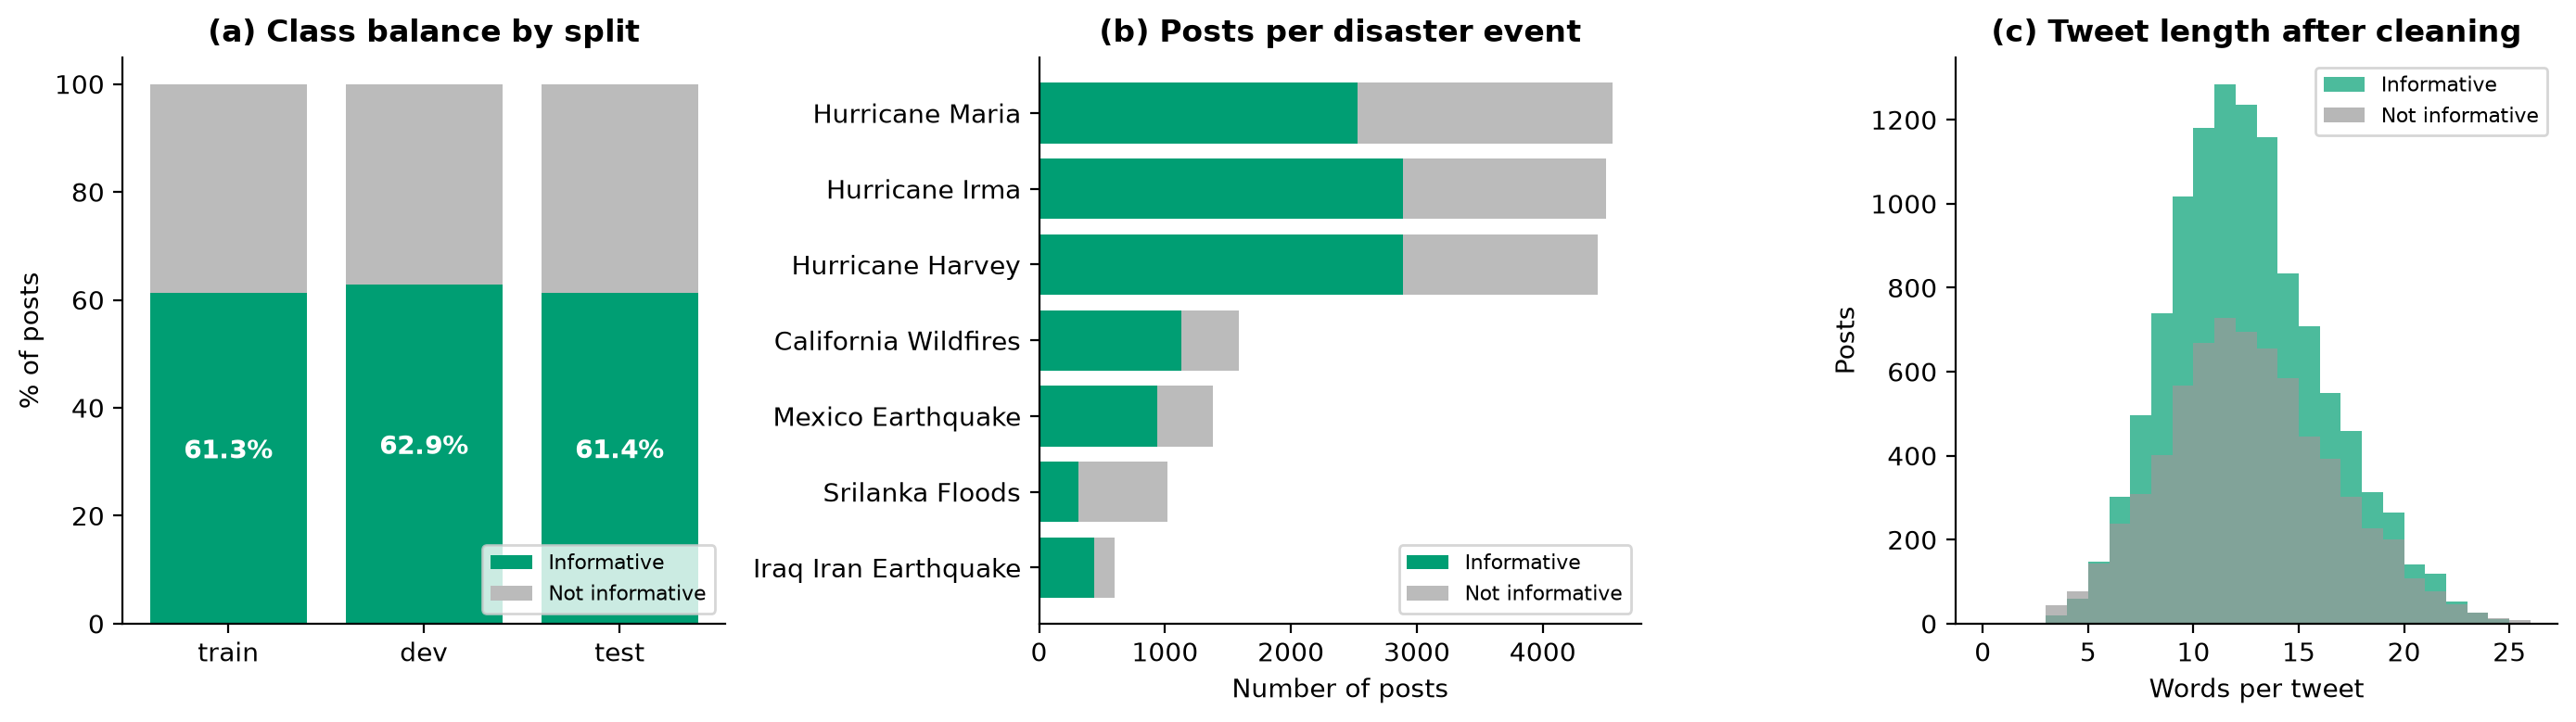

In [38]:
import json
from IPython.display import Image, display
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", device)
print("Local image folder found:", os.path.isdir(C.IMAGE_DIR))

ds = subset(load_crisismmd())
df = add_seen_flag(to_dataframe(ds))
rep = quality_report(df)
print(json.dumps(rep, indent=2, default=str))
display(Image(data_overview(df)))

## 2.2 Download the images

In [39]:
failed = download_images(df.image_path)

Images: 18,082 of 18,082 already on disk, 0 to download -> /Users/paulgtharayil/Downloads/crisismmd-multimodal 4/crisismmd_images/data_image


## 2.3 Extract features

In [40]:
times = extract_all(ds, df, device)
broken = int(sum((~load_pooled(s)["img_ok"]).sum() for s in C.SPLITS))
rep.update({"feature_extraction_sec": times, "broken_images": broken})
json.dump(rep, open(f"{C.RES_DIR}/data_quality.json", "w"), indent=2, default=str)
print(times, "| broken images:", broken)

[train] features found, skipping
[dev] features found, skipping
[test] features found, skipping
{} | broken images: 0


## 2.4. Train and test all models

In [41]:
runs = run_main(df, seeds=C.SEEDS, run_attention=C.RUN_ATTENTION)
by_seed, table, extra = metrics_table(runs, df)
display(table)            # test metrics
display(extra.round(3))   # overfitting  and efficiency

== TF-IDF baseline
== Text only (DistilBERT) | seed 0
  ep  1  train loss 0.401 F1 0.738 | dev loss 0.436 F1 0.700
  ep  2  train loss 0.389 F1 0.750 | dev loss 0.442 F1 0.704
  ep  3  train loss 0.374 F1 0.757 | dev loss 0.441 F1 0.695
  ep  4  train loss 0.362 F1 0.768 | dev loss 0.449 F1 0.704
  ep  5  train loss 0.345 F1 0.793 | dev loss 0.444 F1 0.703
  ep  6  train loss 0.337 F1 0.796 | dev loss 0.448 F1 0.691
  ep  7  train loss 0.327 F1 0.793 | dev loss 0.460 F1 0.690
  ep  8  train loss 0.312 F1 0.812 | dev loss 0.466 F1 0.685
== Image only (EfficientNet-B0) | seed 0
  ep  1  train loss 0.384 F1 0.761 | dev loss 0.414 F1 0.721
  ep  2  train loss 0.350 F1 0.789 | dev loss 0.412 F1 0.717
  ep  3  train loss 0.319 F1 0.804 | dev loss 0.424 F1 0.721
  ep  4  train loss 0.292 F1 0.822 | dev loss 0.432 F1 0.718
  ep  5  train loss 0.264 F1 0.854 | dev loss 0.444 F1 0.706
  ep  6  train loss 0.231 F1 0.876 | dev loss 0.461 F1 0.705
  ep  7  train loss 0.206 F1 0.883 | dev loss 0.477

,macro_f1,accuracy,precision,recall,recall_inf,auroc
model,,,,,,
TF-IDF + LogReg (text),0.704 ± 0.000,0.722 ± 0.000,0.706 ± 0.000,0.703 ± 0.000,0.787 ± 0.000,0.763 ± 0.000
Text only (DistilBERT),0.716 ± 0.008,0.734 ± 0.008,0.719 ± 0.008,0.714 ± 0.009,0.798 ± 0.009,0.789 ± 0.004
Image only (EfficientNet-B0),0.722 ± 0.007,0.726 ± 0.007,0.724 ± 0.007,0.736 ± 0.008,0.694 ± 0.018,0.805 ± 0.006
Early fusion,0.758 ± 0.007,0.770 ± 0.007,0.758 ± 0.007,0.758 ± 0.006,0.811 ± 0.009,0.858 ± 0.006
Late fusion,0.765 ± 0.007,0.774 ± 0.008,0.763 ± 0.008,0.771 ± 0.008,0.782 ± 0.026,0.856 ± 0.005
Cross-attention fusion,0.761 ± 0.003,0.771 ± 0.006,0.760 ± 0.005,0.764 ± 0.002,0.795 ± 0.034,0.856 ± 0.007


,train_macro_f1,dev_macro_f1,macro_f1,gap_train_minus_test,params,train_sec,infer_ms_per_1k,best_epoch
model,,,,,,,,
TF-IDF + LogReg (text),0.785,0.677,0.704,0.081,20241.0,1.219,10.506,NaN
Text only (DistilBERT),0.764,0.710,0.716,0.048,197121.0,6.432,3.696,3.000
Image only (EfficientNet-B0),0.789,0.723,0.722,0.068,328193.0,8.060,4.174,2.333
Early fusion,0.871,0.762,0.758,0.113,524801.0,7.861,4.926,3.333
Late fusion,0.829,0.756,0.765,0.063,525314.0,14.491,7.870,NaN
Cross-attention fusion,0.841,0.763,0.761,0.080,2249473.0,80.839,132.202,3.000


## 2.5. Evaluation figures

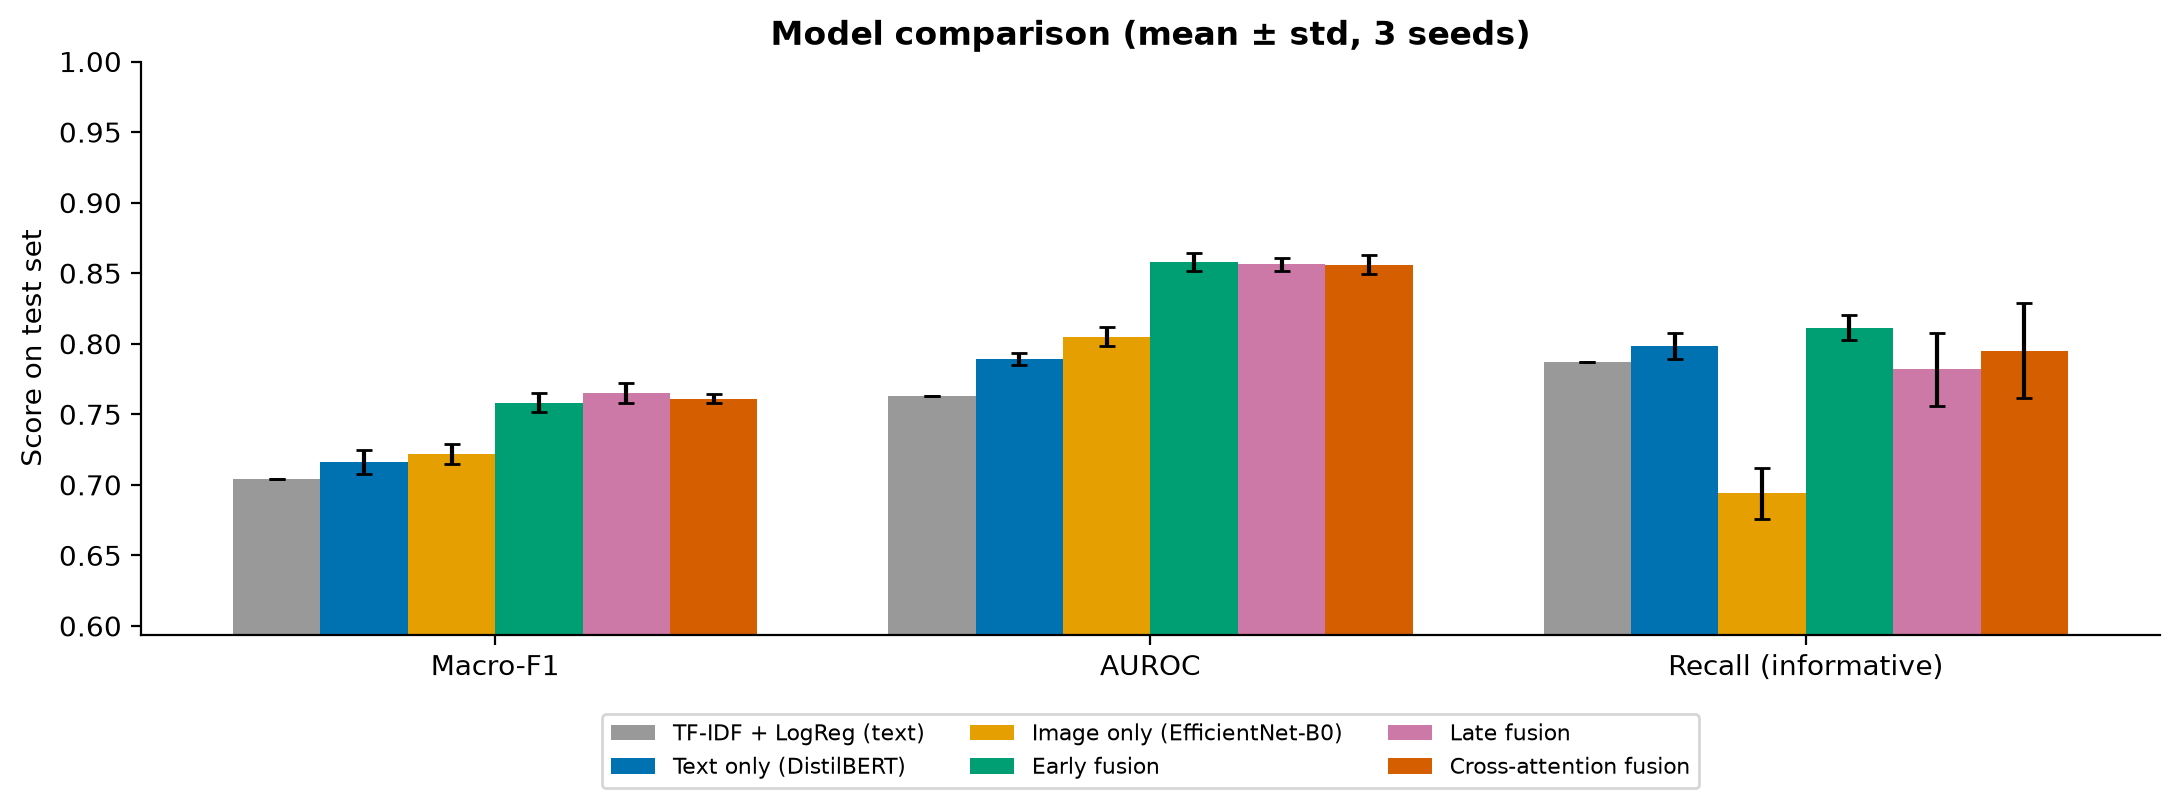

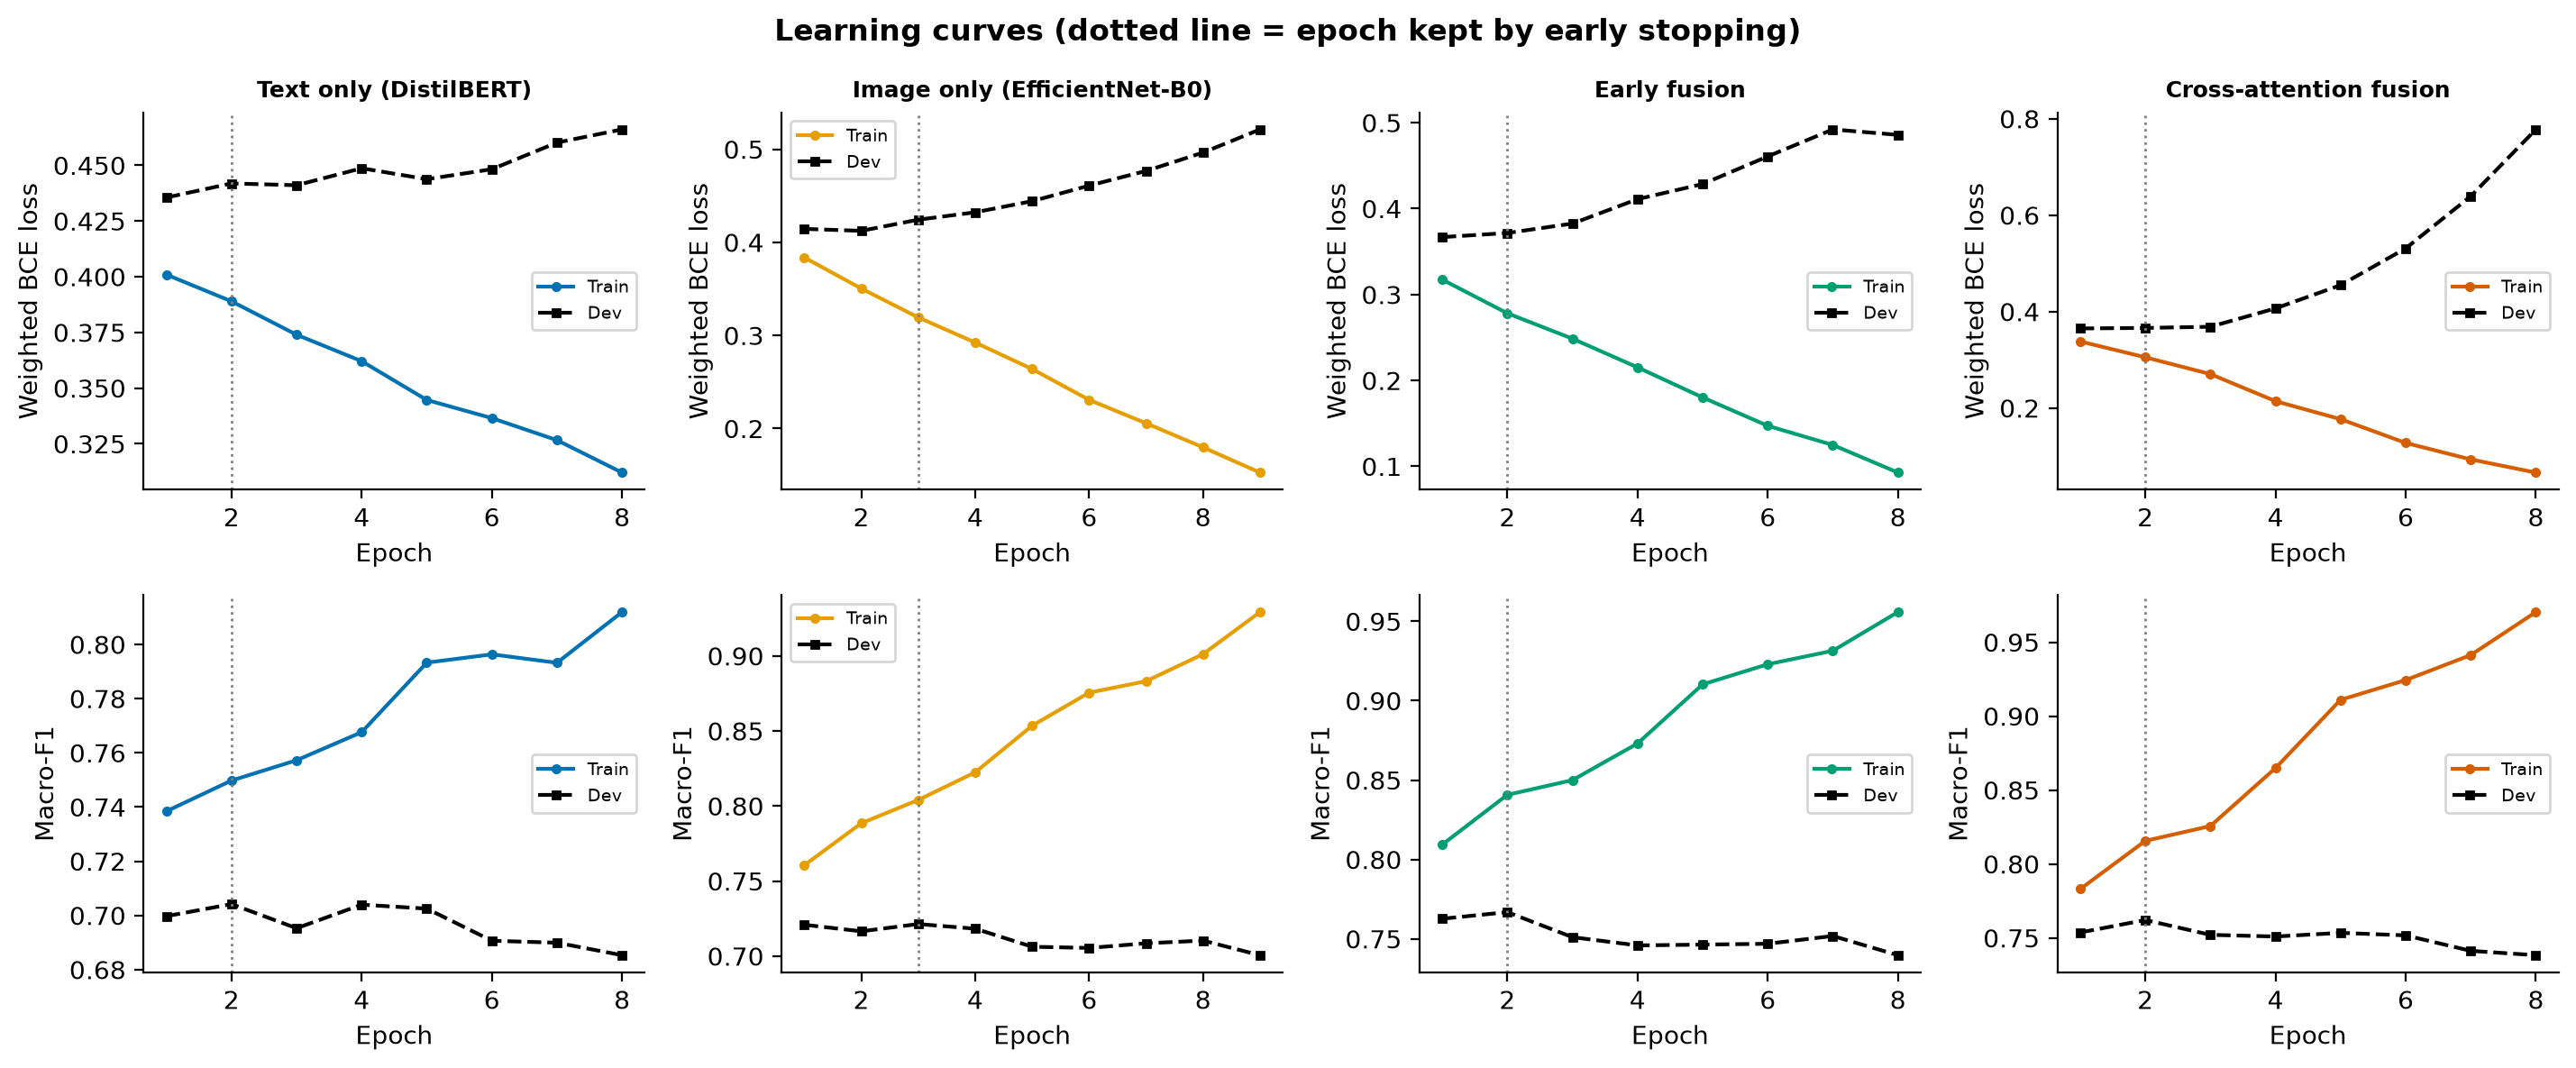

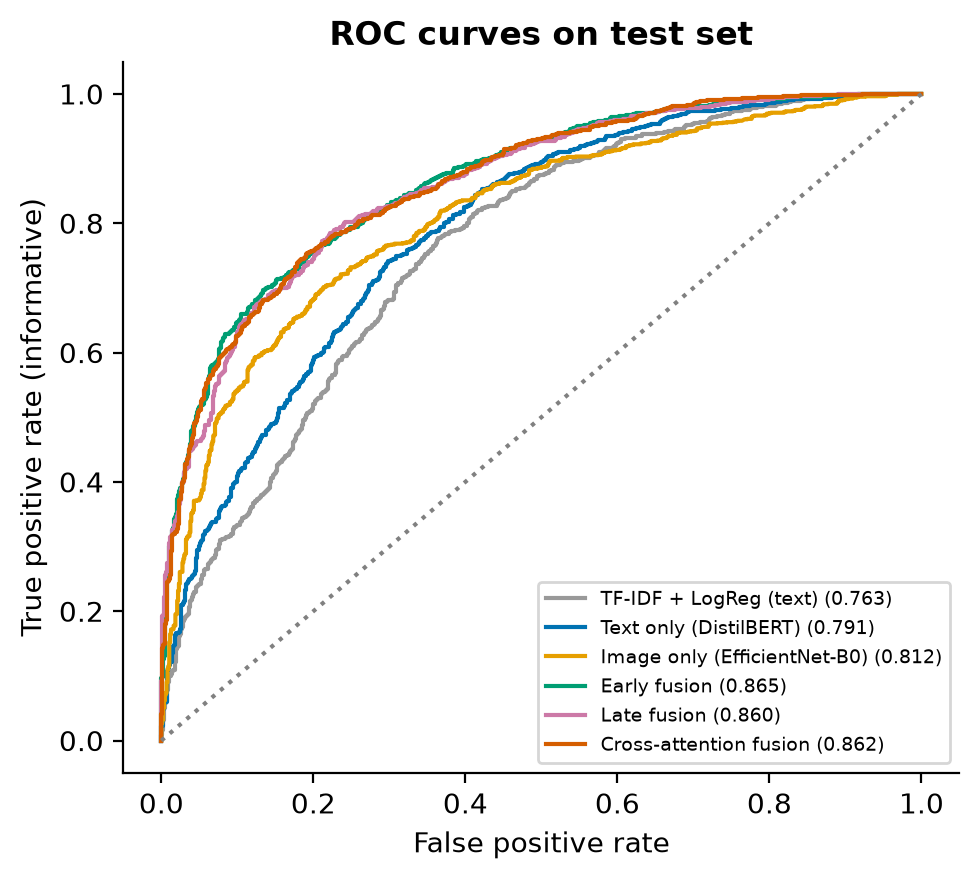

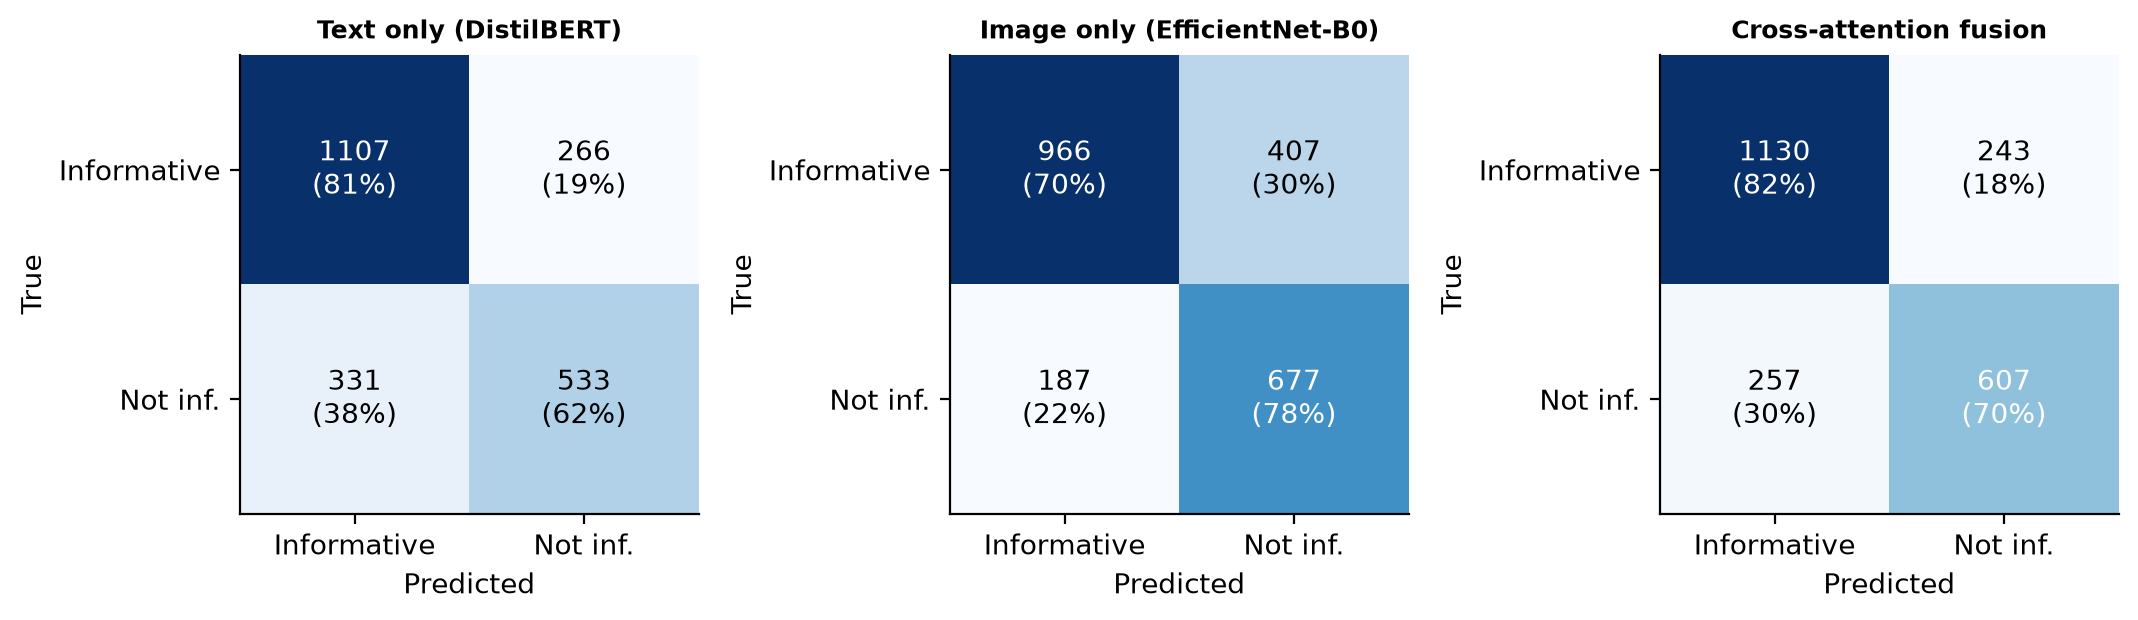

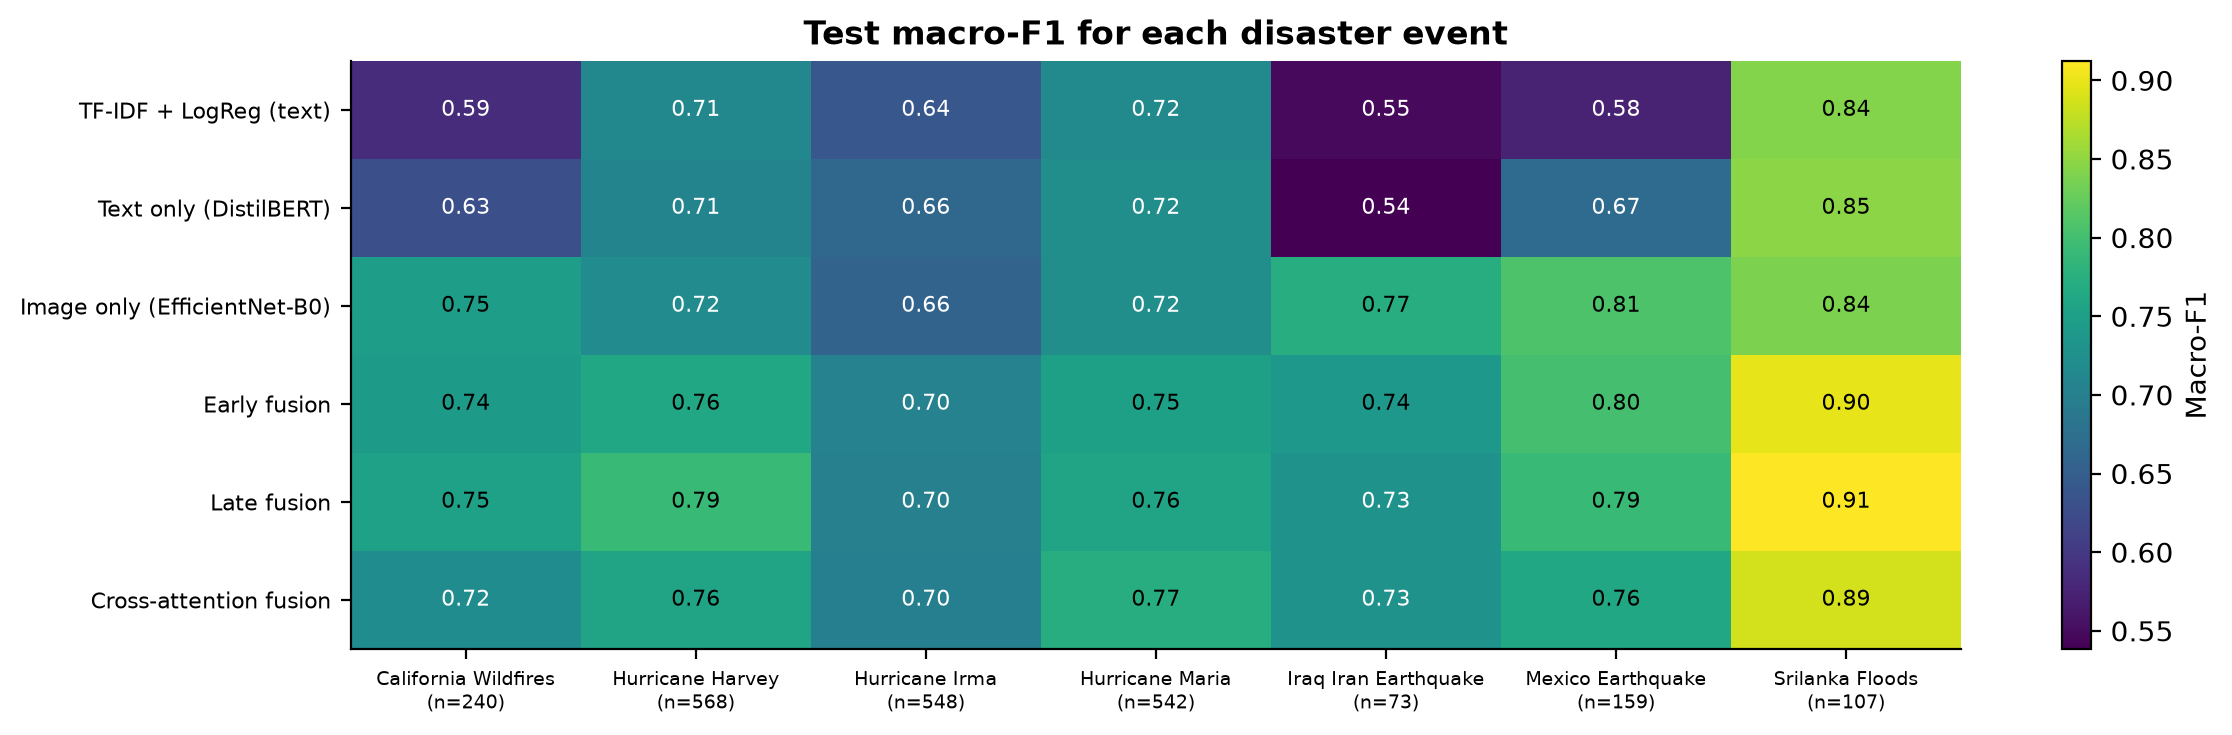

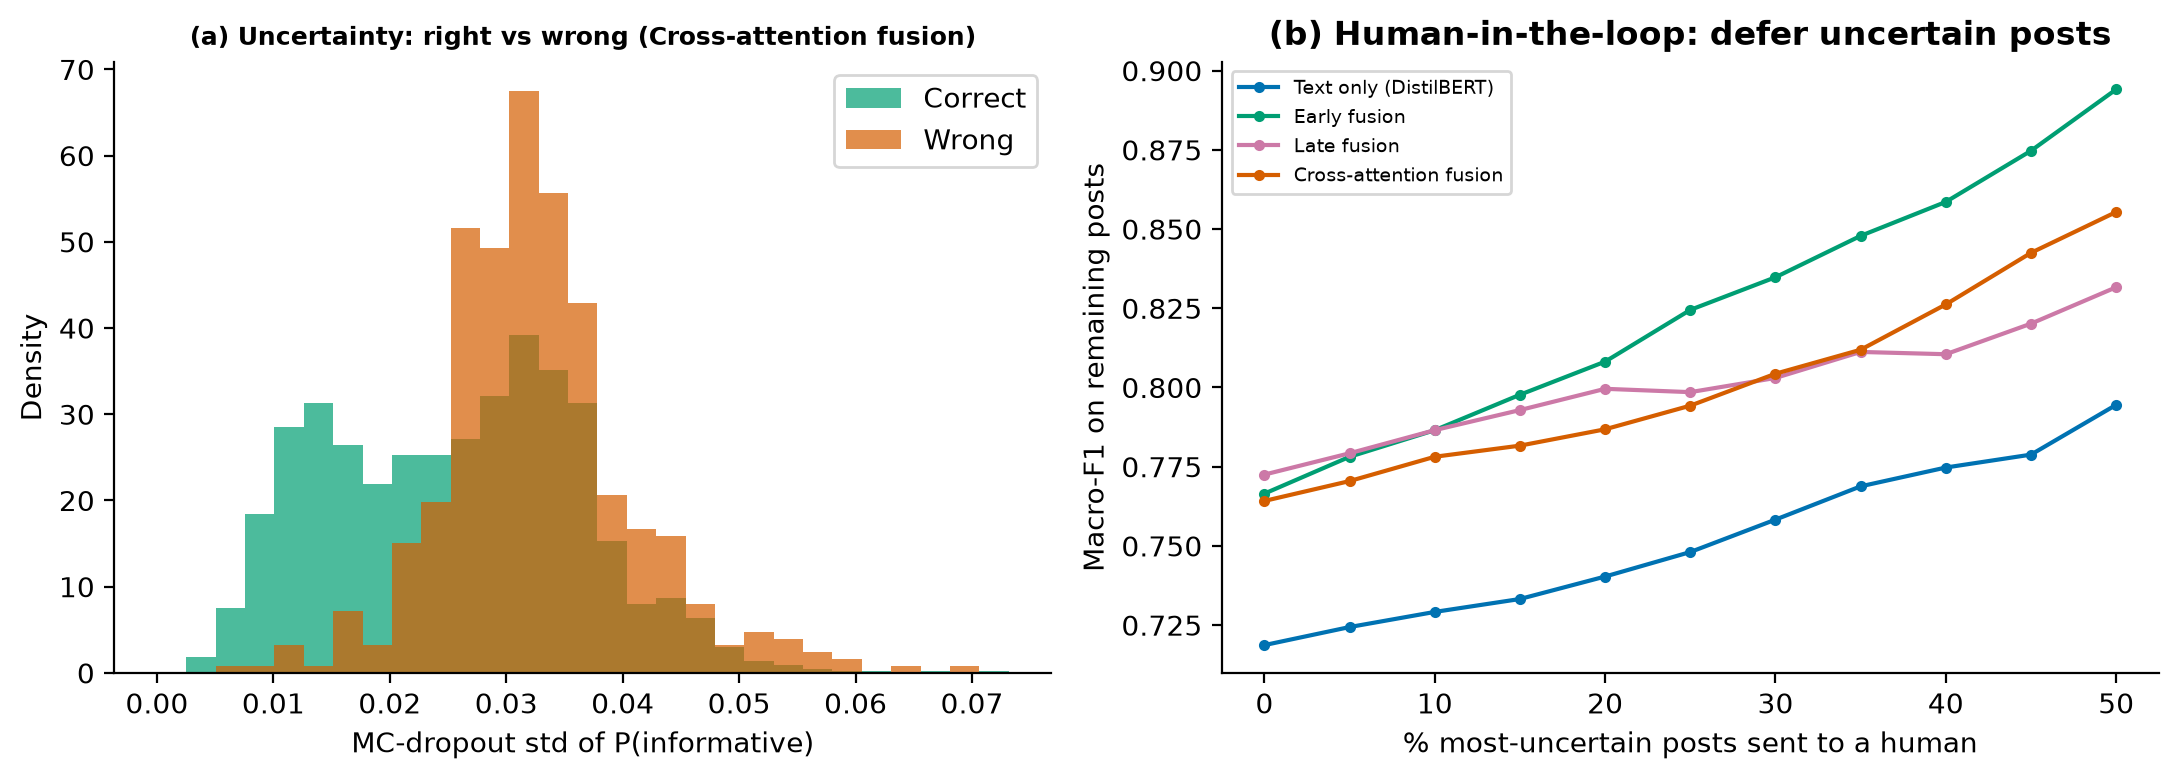

In [42]:
best = M_ATTN if M_ATTN in runs else M_EARLY
unc_models = [m for m in [M_TEXT, M_EARLY, M_LATE, M_ATTN] if m in runs]
for f in [model_comparison(by_seed), learning_curves(runs), roc_curves(runs, df),
          confusion(runs, df, [M_TEXT, M_IMG, best]), per_event_heatmap(runs, df),
          uncertainty_plot(runs, df, unc_models)]:
    display(Image(f))

In [43]:
display(agreement_table(runs, df, other=M_EARLY))
if M_ATTN in runs:
    display(agreement_table(runs, df, other=M_ATTN))
display(seen_unseen_table(runs, df))

,both right,fixed by fusion,broken by fusion,both wrong
Text only (DistilBERT) vs Early fusion,1495,246,145,351


,both right,fixed by fusion,broken by fusion,both wrong
Text only (DistilBERT) vs Cross-attention fusion,1495,242,145,355


subset,new text
model,
Cross-attention fusion,0.763563
Early fusion,0.765865
Image only (EfficientNet-B0),0.729959
Late fusion,0.772422
TF-IDF + LogReg (text),0.704267
Text only (DistilBERT),0.714315


## 2.6. Generalisation to a new disaster 


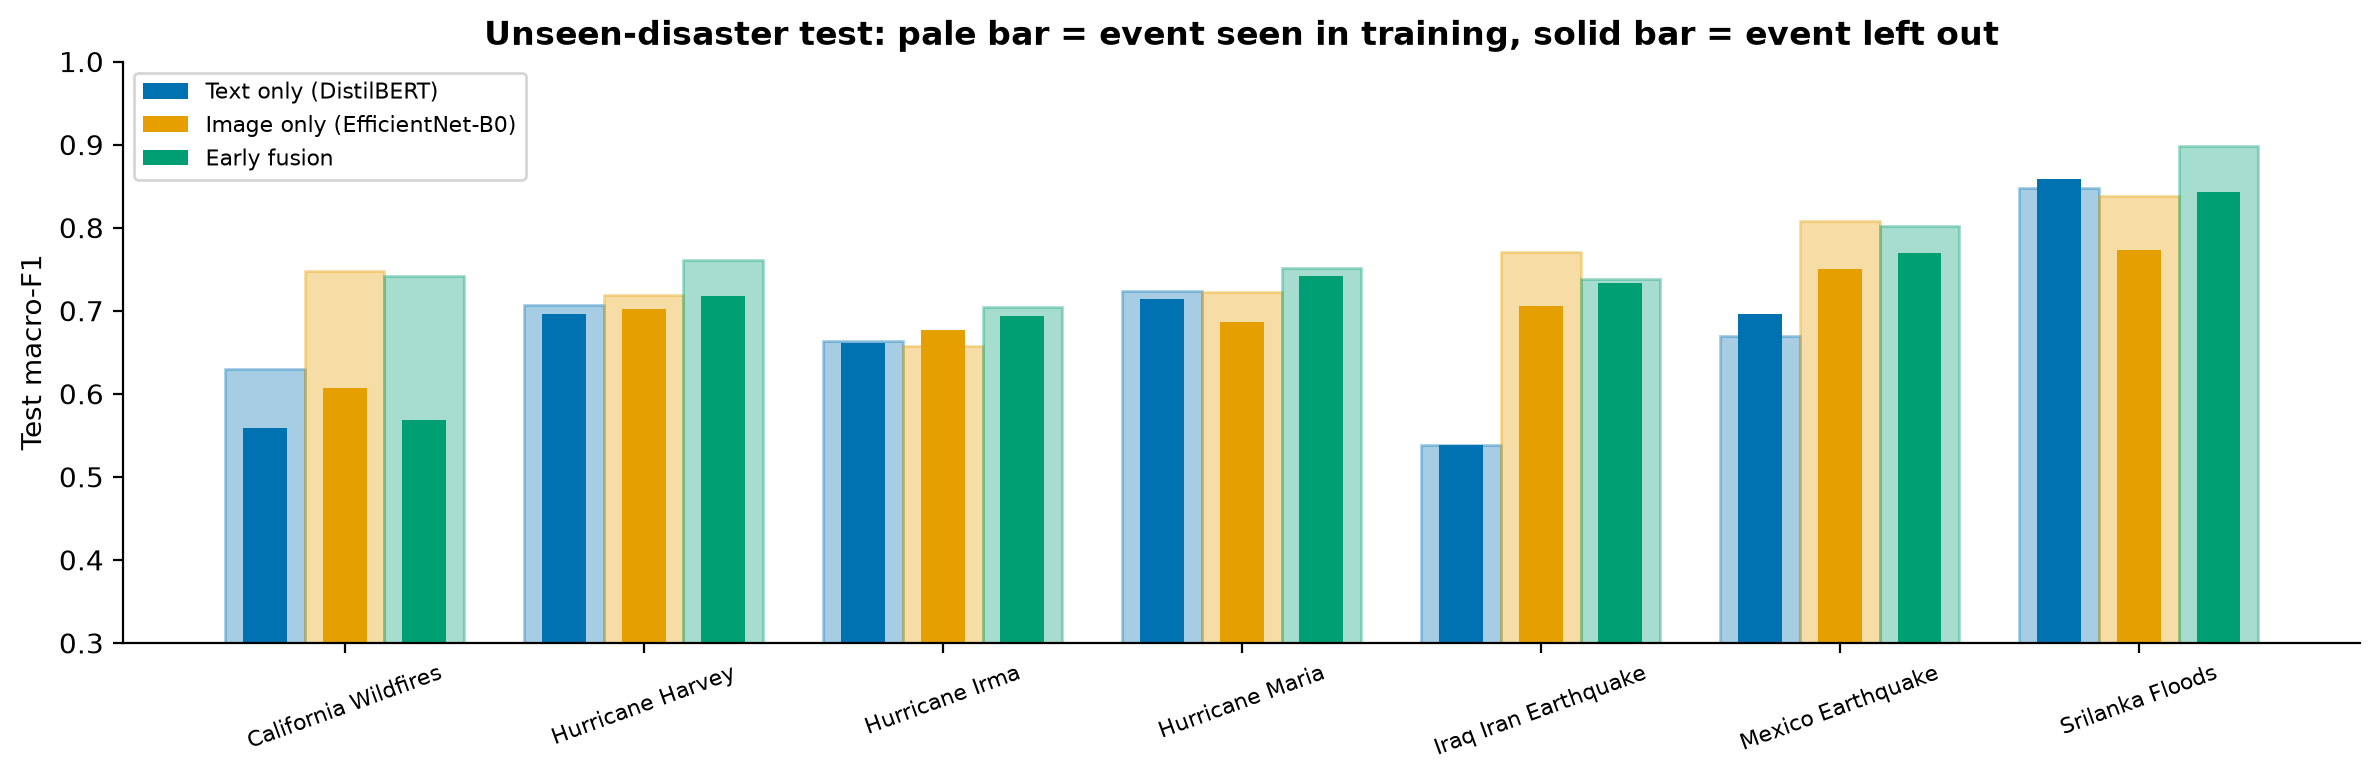

,in_dist,unseen_event,drop
model,,,
Early fusion,0.771,0.724,0.047
Image only (EfficientNet-B0),0.752,0.700,0.052
Text only (DistilBERT),0.683,0.675,0.008


In [44]:
if C.RUN_LOEO:
    loeo = run_leave_one_event_out(df)
    f, t = loeo_plot(loeo, runs, df)
    display(Image(f))
    display(t.groupby("model")[["in_dist", "unseen_event", "drop"]].mean().round(3))

## 2.7. Failure cases and attention maps

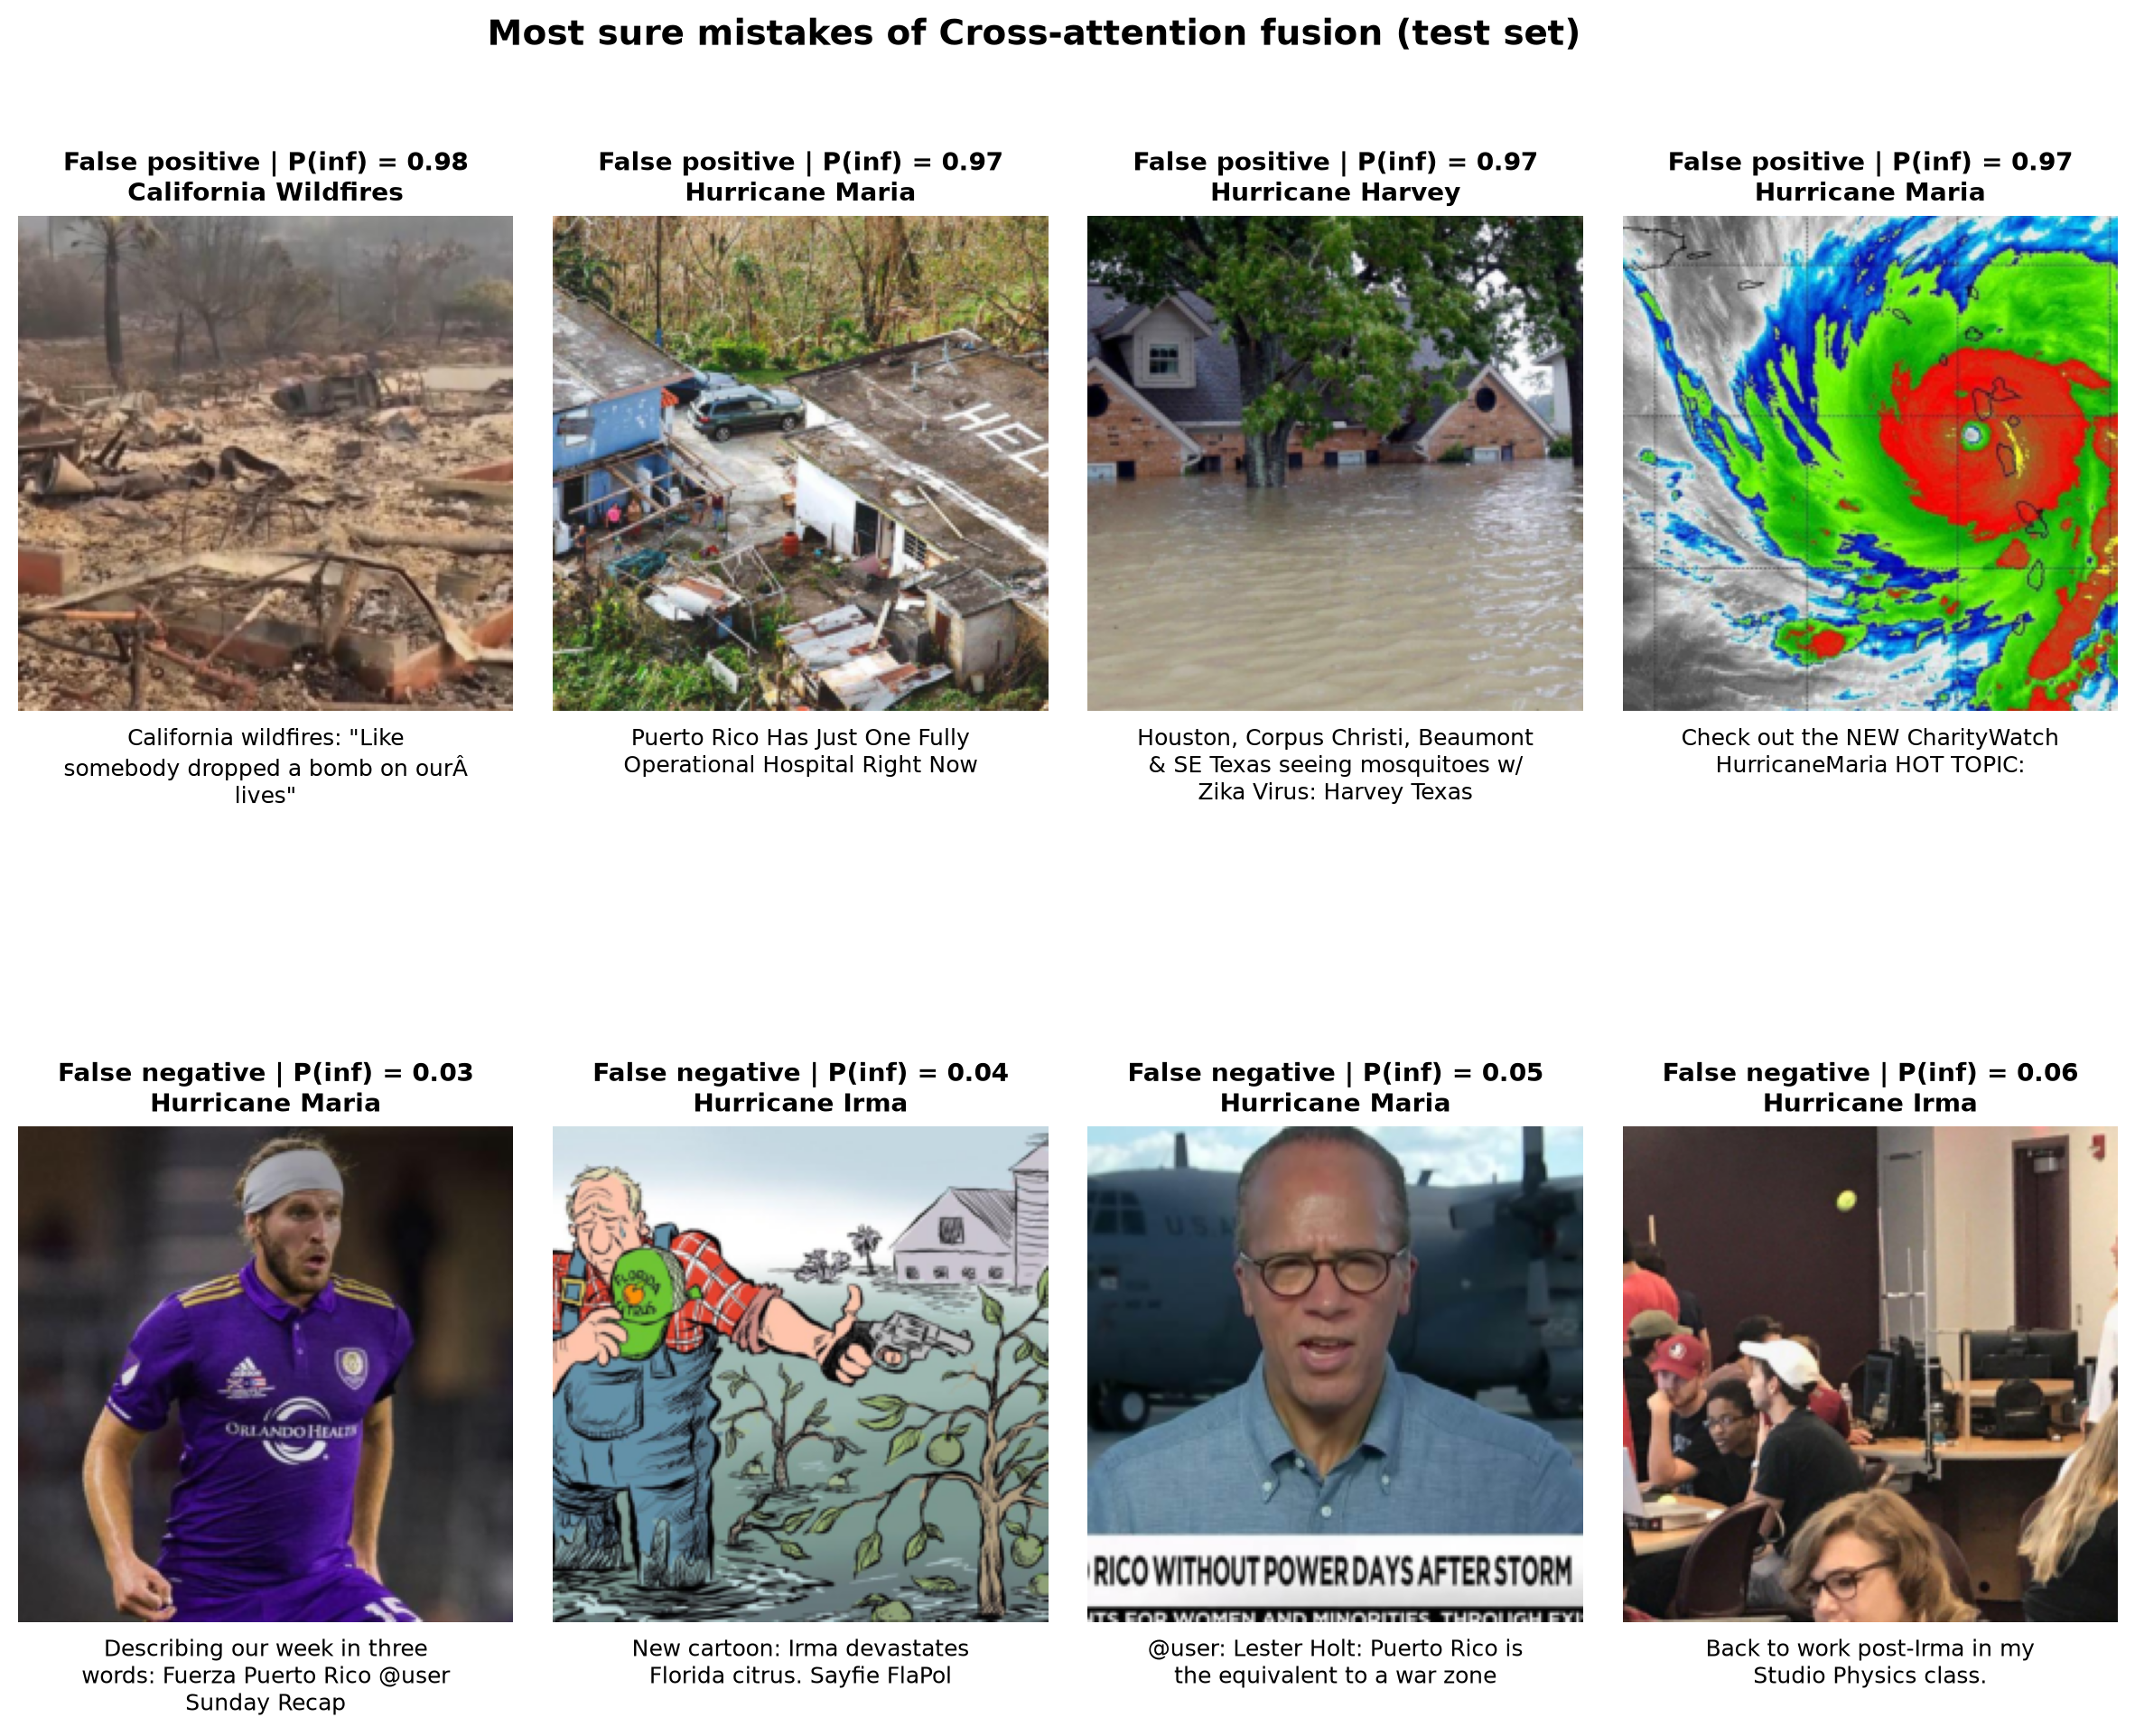

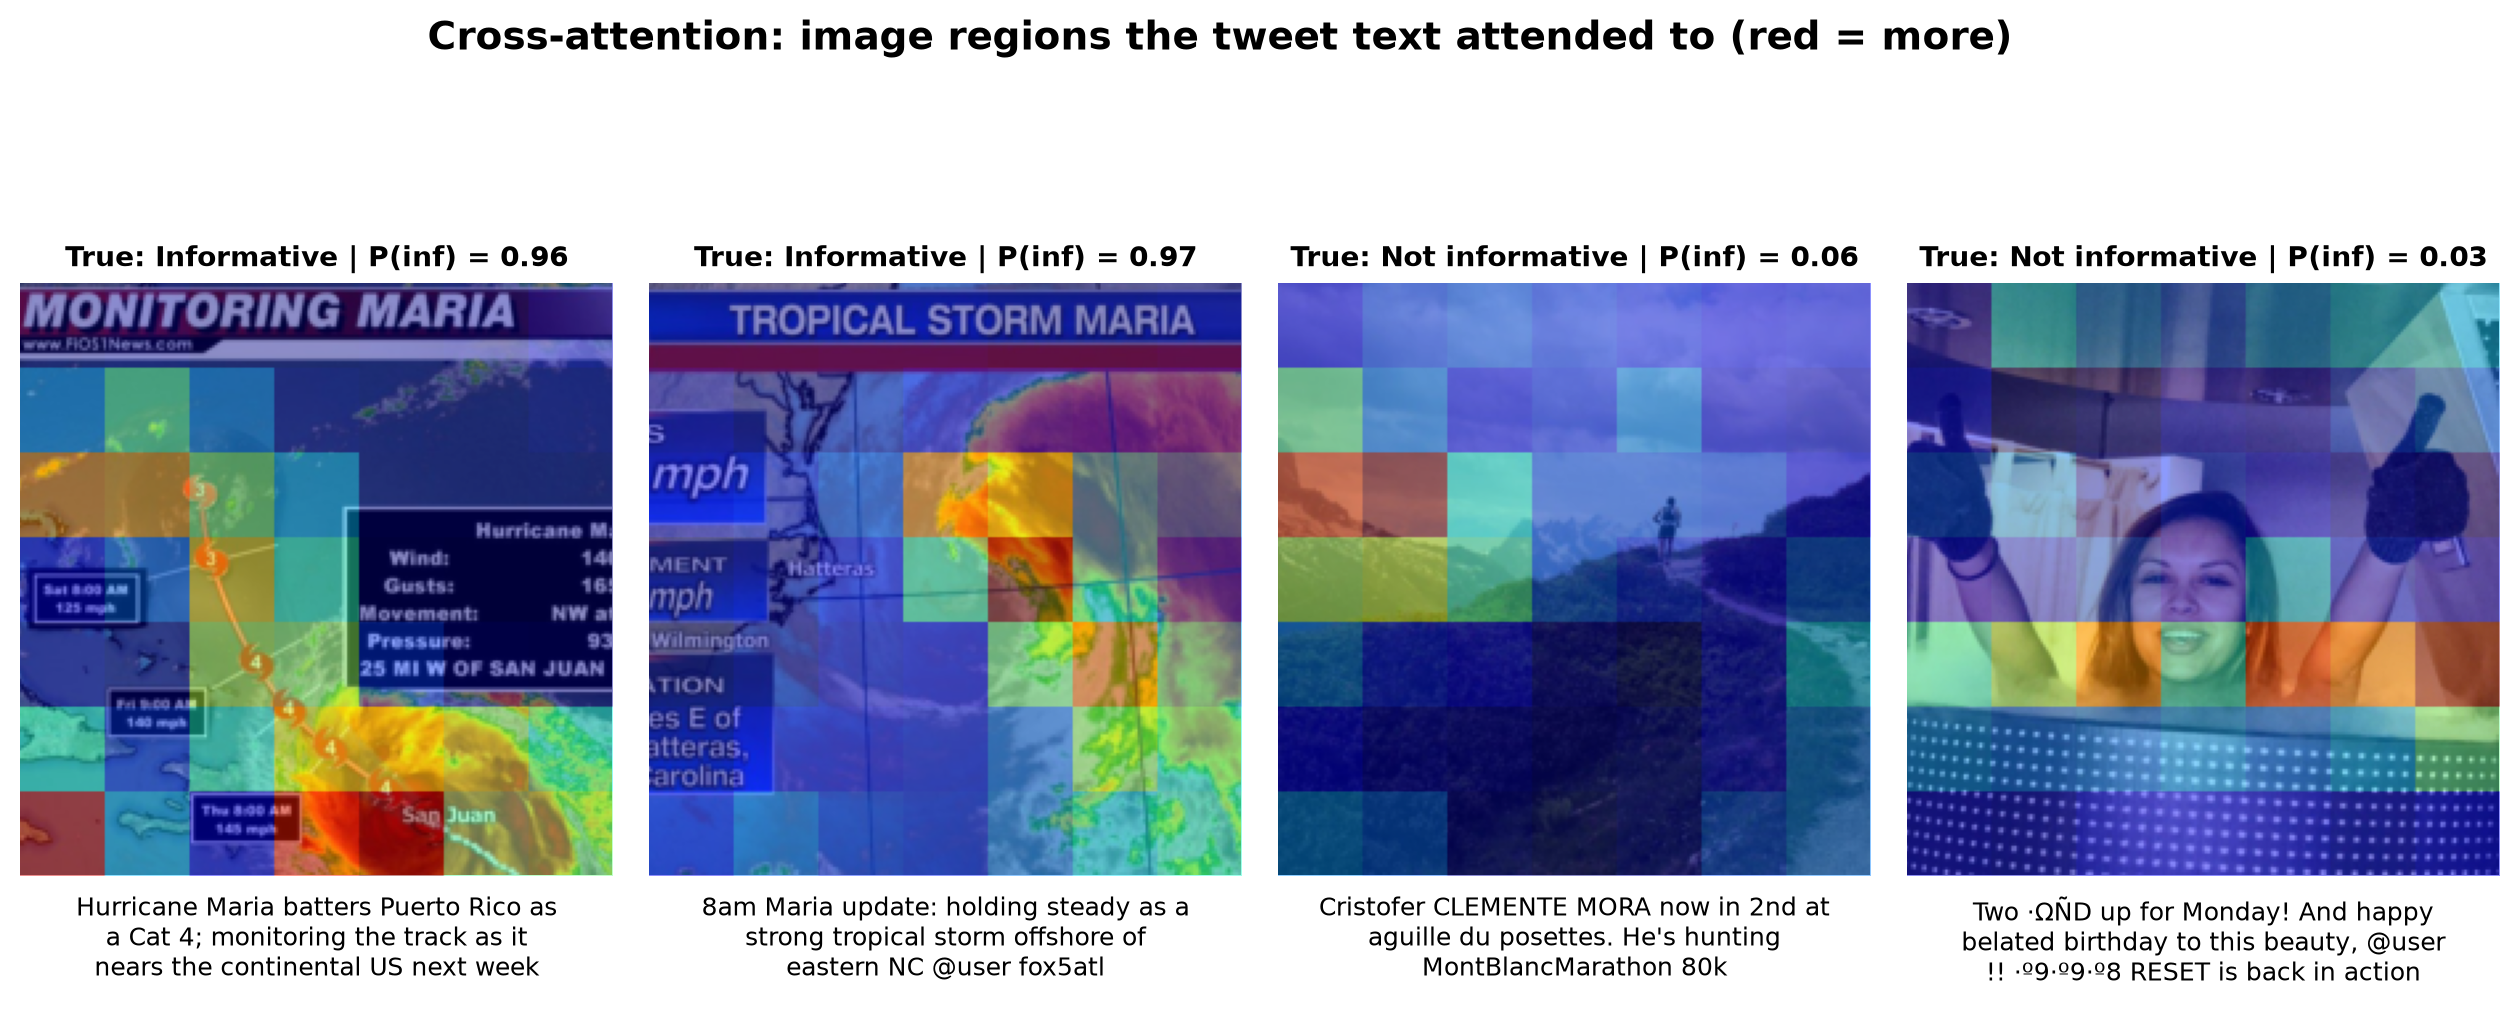

In [45]:
display(Image(failure_gallery(ds, df, runs[best][0]["test"], best)))

if M_ATTN in runs:
    model = CrossAttnFusion()
    model.load_state_dict(torch.load(f"{C.RES_DIR}/cross_attention_seed0.pt", map_location=device))
    feeder = TokenFeeder({"test": load_tokens("test")})
    test = df[df.split == "test"].sort_values("row").reset_index(drop=True)
    p = runs[M_ATTN][0]["test"]
    pick = list(np.where((p > .9) & (test.y == 1))[0][:2]) +list(np.where((p <.1) &(test.y == 0))[0][:2])
    display(Image(attention_maps(model, feeder, ds, df, pick, device)))